In [1]:
import ast
import hashlib
from collections import Counter
from dataclasses import dataclass
from itertools import chain
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb
from scipy.signal import welch

In [2]:
PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATABASE_FILE = "ptbxl_database.csv"
STATEMENTS_FILE = "scp_statements.csv"
LOW_RATE = 100
HIGH_RATE = 500
RATE_FILENAME_COLUMNS = {LOW_RATE: "filename_lr", HIGH_RATE: "filename_hr"}
LEAD_NAMES = ("I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6")
LEAD_GRID = (6, 2)
REFERENCE_LEAD = "II"
SUPERCLASSES = ("NORM", "MI", "STTC", "CD", "HYP")
STATEMENT_CATEGORIES = ("diagnostic", "form", "rhythm")
SEX_LABELS = {0: "male", 1: "female"}
MAX_PLAUSIBLE_AGE = 120
CAPPED_AGE = 90
LABEL_QUALITY_COLUMNS = ("validated_by_human", "second_opinion", "initial_autogenerated_report")
ACQUISITION_COLUMNS = ("site", "device", "nurse")
SIGNAL_QUALITY_COLUMNS = ("static_noise", "burst_noise", "baseline_drift", "electrodes_problems", "extra_beats", "pacemaker")
LIKELIHOOD_THRESHOLDS = (0, 15, 35, 50, 80, 100)
RANDOM_SEED = 42
SIGNAL_SAMPLE_SIZE = 500
SPECTRUM_SAMPLE_SIZE = 200
TOP_CATEGORY_COUNT = 15
ZOOM_HALF_WIDTH_SECONDS = 0.3
FLATLINE_STD_THRESHOLD = 0.01
CLIPPING_FRACTION_THRESHOLD = 0.02
BASE_FIGURE_SIZE = (12, 5)
WIDE_FIGURE_SIZE = (18, 6)
SQUARE_FIGURE_SIZE = (8, 7)
LEAD_FIGURE_SIZE = (16, 14)
COMPARISON_ROW_HEIGHT = 2.0
FIGURE_DPI = 110
PRIMARY_COLOR = "#2E5E8C"
SECONDARY_COLOR = "#E07A5F"
NEUTRAL_COLOR = "#9AA5B1"
SEQUENTIAL_CMAP = "Blues"
SUPERCLASS_COLORS = {"NORM": "#4C9F70", "MI": "#D1495B", "STTC": "#EDAE49", "CD": "#00798C", "HYP": "#7B5EA7"}
SEX_COLORS = {"male": PRIMARY_COLOR, "female": SECONDARY_COLOR}
MIN_ADULT_AGE = 18
MODEL_METADATA_COLUMNS = ("patient_id", "age", "sex", "strat_fold")
GAP_DAY_EDGES = (-1, 0, 7, 30, 365, np.inf)
GAP_DAY_LABELS = ("same day", "1-7 days", "8-30 days", "31-365 days", "over 1 year")
FOLD_HEATMAP_SIZE = (14, 7)

In [3]:
class PlotTheme:
    @staticmethod
    def apply():
        sns.set_theme(style="whitegrid", context="notebook")
        plt.rcParams.update({
            "figure.figsize": BASE_FIGURE_SIZE,
            "figure.dpi": FIGURE_DPI,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "axes.labelsize": 11,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "legend.frameon": False
        })

    @staticmethod
    def class_colors(labels):
        return [SUPERCLASS_COLORS.get(label, NEUTRAL_COLOR) for label in labels]

    @staticmethod
    def figure(nrows=1, ncols=1, size=BASE_FIGURE_SIZE, sharex=False, sharey=False):
        return plt.subplots(nrows, ncols, figsize=size, sharex=sharex, sharey=sharey, constrained_layout=True)

    @staticmethod
    def decorate(ax, title, xlabel=None, ylabel=None):
        ax.set_title(title)
        ax.set_xlabel(xlabel or "")
        ax.set_ylabel(ylabel or "")

PlotTheme.apply()

In [4]:
class MetadataRepository:
    def __init__(self, raw_dir):
        self.raw_dir = raw_dir

    def load_database(self):
        database = pd.read_csv(self.raw_dir / DATABASE_FILE, index_col="ecg_id")
        database["scp_codes"] = database["scp_codes"].apply(ast.literal_eval)
        database["device"] = database["device"].str.split().str.join(" ")
        return database

    def load_statements(self):
        statements = pd.read_csv(self.raw_dir / STATEMENTS_FILE, index_col=0)
        statements.index.name = "statement"
        return statements

class LabelHierarchy:
    def __init__(self, statements):
        diagnostic = statements[statements["diagnostic"] == 1]
        self.subclass_of = diagnostic["diagnostic_subclass"].to_dict()
        self.superclass_of = diagnostic["diagnostic_class"].to_dict()
        self.parent_of_subclass = diagnostic.groupby("diagnostic_subclass")["diagnostic_class"].first().to_dict()
        self.category_members = {category: set(statements.index[statements[category] == 1]) for category in STATEMENT_CATEGORIES}

    @staticmethod
    def confident_statements(codes, threshold=0):
        return [code for code, likelihood in codes.items() if likelihood >= threshold]

    def subclasses(self, codes, threshold=0):
        return sorted({self.subclass_of[code] for code in self.confident_statements(codes, threshold) if code in self.subclass_of})

    def superclasses(self, codes, threshold=0):
        return sorted({self.superclass_of[code] for code in self.confident_statements(codes, threshold) if code in self.superclass_of})

class LabelMatrix:
    @staticmethod
    def from_lists(label_lists, classes):
        return pd.DataFrame({label: label_lists.apply(lambda labels: label in labels) for label in classes}).astype(int)

    @staticmethod
    def combination_key(labels):
        return "+".join(labels) or "NONE"

    @staticmethod
    def combination_keys(label_lists, min_count):
        keys = label_lists.apply(LabelMatrix.combination_key)
        return keys.where(keys.map(keys.value_counts()) >= min_count, "RARE")

    @staticmethod
    def co_occurrence(matrix):
        return matrix.T @ matrix

In [5]:
class SignalRepository:
    def __init__(self, raw_dir, database):
        self.raw_dir = raw_dir
        self.database = database

    def path(self, ecg_id, rate):
        return self.raw_dir / self.database.at[ecg_id, RATE_FILENAME_COLUMNS[rate]]

    def exists(self, ecg_id, rate):
        path = self.path(ecg_id, rate)
        return path.with_suffix(".dat").exists() and path.with_suffix(".hea").exists()

    def header(self, ecg_id, rate):
        return wfdb.rdheader(str(self.path(ecg_id, rate)))

    def load(self, ecg_id, rate):
        signal, _ = wfdb.rdsamp(str(self.path(ecg_id, rate)))
        return signal

    def load_many(self, ecg_ids, rate):
        return np.stack([self.load(ecg_id, rate) for ecg_id in ecg_ids])

class SignalInspector:
    @staticmethod
    def time_axis(signal, rate):
        return np.arange(signal.shape[0]) / rate

    @staticmethod
    def peak_time(signal, rate, lead_index):
        lead = signal[:, lead_index]
        return np.argmax(np.abs(lead - np.median(lead))) / rate

    @staticmethod
    def power_spectrum(batch, rate):
        return welch(batch, fs=rate, nperseg=rate * 2, axis=1)

    @staticmethod
    def integrity_report(signal):
        at_extremes = (signal == signal.max(axis=0)) | (signal == signal.min(axis=0))
        return {
            "length": signal.shape[0],
            "non_finite": int((~np.isfinite(signal)).sum()),
            "flat_leads": int((signal.std(axis=0) < FLATLINE_STD_THRESHOLD).sum()),
            "clipped_leads": int((at_extremes.mean(axis=0) > CLIPPING_FRACTION_THRESHOLD).sum()),
            "fingerprint": hashlib.sha1(signal.tobytes()).hexdigest()
        }

class RecordSelector:
    def __init__(self, database, rng):
        self.database = database
        self.rng = rng
        self.clean = database[list(SIGNAL_QUALITY_COLUMNS)].isna().all(axis=1)
        self.validated = database["validated_by_human"].astype(bool)

    def pick(self, mask):
        return self.rng.choice(self.database.index[mask])

    def single_superclass(self, superclass):
        return self.pick(self.database["superclasses"].apply(lambda labels: labels == [superclass]) & self.validated & self.clean)

    def clean_record(self):
        return self.pick(self.clean & self.validated)

    def flagged_record(self, column):
        return self.pick(self.database[column].notna())

In [6]:
@dataclass(frozen=True)
class Trace:
    label: str
    time: np.ndarray
    values: np.ndarray
    color: str
    marker: str = ""

class Charts:
    @staticmethod
    def bar(
        series,
        title,
        xlabel=None,
        ylabel="Count",
        color=PRIMARY_COLOR,
        horizontal=False,
        size=BASE_FIGURE_SIZE,
        rotation=0,
        value_format="%d",
        annotate=True
    ):
        _, ax = PlotTheme.figure(size=size)
        labels = series.index.astype(str)
        bars = ax.barh(labels, series.values, color=color) if horizontal else ax.bar(labels, series.values, color=color)
        if horizontal:
            ax.invert_yaxis()
        ax.tick_params(axis="x", rotation=rotation)
        if annotate:
            ax.bar_label(bars, fmt=value_format, padding=2, fontsize=9)
        PlotTheme.decorate(ax, title, ylabel if horizontal else xlabel, xlabel if horizontal else ylabel)
        plt.show()

    @staticmethod
    def histogram(values, title, xlabel, bins=50, color=PRIMARY_COLOR, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        ax.hist(values.dropna(), bins=bins, color=color, edgecolor="white")
        PlotTheme.decorate(ax, title, xlabel, "Count")
        plt.show()

    @staticmethod
    def histogram_grid(frame, columns, title, bins=50, color=PRIMARY_COLOR):
        fig, axes = PlotTheme.figure(ncols=len(columns))
        for ax, column in zip(axes, columns):
            ax.hist(frame[column].dropna(), bins=bins, color=color, edgecolor="white")
            PlotTheme.decorate(ax, column, column, "Count")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def distribution_by_group(frame, value_column, group_column, title, xlabel, palette, bins=40):
        _, ax = PlotTheme.figure()
        sns.histplot(frame, x=value_column, hue=group_column, palette=palette, bins=bins, stat="density", common_norm=False, element="step", ax=ax)
        PlotTheme.decorate(ax, title, xlabel, "Density")
        plt.show()

    @staticmethod
    def box_by_group(frame, value_column, group_column, title, ylabel, order=None, palette=None, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        sns.boxplot(frame, x=group_column, y=value_column, hue=group_column, order=order, palette=palette, legend=False, showfliers=False, ax=ax)
        PlotTheme.decorate(ax, title, group_column, ylabel)
        plt.show()

    @staticmethod
    def heatmap(matrix, title, value_format="d", size=SQUARE_FIGURE_SIZE, cmap=SEQUENTIAL_CMAP):
        _, ax = PlotTheme.figure(size=size)
        sns.heatmap(matrix, annot=True, fmt=value_format, cmap=cmap, linewidths=0.5, ax=ax)
        PlotTheme.decorate(ax, title)
        plt.show()

    @staticmethod
    def grouped_bar(frame, title, xlabel, ylabel, colors=None, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        frame.plot(kind="bar", color=colors, width=0.8, ax=ax)
        ax.tick_params(axis="x", rotation=0)
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        PlotTheme.decorate(ax, title, xlabel, ylabel)
        plt.show()

    @staticmethod
    def lines(frame, title, xlabel, ylabel, colors=None, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        frame.plot(marker="o", color=colors, ax=ax)
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        PlotTheme.decorate(ax, title, xlabel, ylabel)
        plt.show()

    @staticmethod
    def leads(signal, rate, title, color=PRIMARY_COLOR):
        time = SignalInspector.time_axis(signal, rate)
        fig, axes = PlotTheme.figure(nrows=LEAD_GRID[0], ncols=LEAD_GRID[1], size=LEAD_FIGURE_SIZE, sharex=True)
        for lead_index, ax in enumerate(axes.flatten(order="F")):
            ax.plot(time, signal[:, lead_index], color=color, linewidth=0.8)
            ax.set_ylabel(LEAD_NAMES[lead_index], rotation=0, labelpad=18)
        for ax in axes[-1]:
            ax.set_xlabel("Time (s)")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def overlay(traces, title, xlabel, ylabel, xlim=None, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        for trace in traces:
            ax.plot(trace.time, trace.values, color=trace.color, marker=trace.marker, markersize=4, linewidth=1, label=trace.label)
        if xlim:
            ax.set_xlim(xlim)
        ax.legend()
        PlotTheme.decorate(ax, title, xlabel, ylabel)
        plt.show()

    @staticmethod
    def spectrum(power, title, marker_frequency, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        for lead, color in zip(power.columns, sns.color_palette("husl", len(power.columns))):
            ax.semilogy(power.index, power[lead], color=color, linewidth=0.9, label=lead)
        ax.axvline(marker_frequency, color=NEUTRAL_COLOR, linestyle="--", label=f"{marker_frequency:g} Hz")
        ax.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
        PlotTheme.decorate(ax, title, "Frequency (Hz)", "Power (mV²/Hz)")
        plt.show()

    @staticmethod
    def lead_comparison(signals_by_label, rate, lead_index, title, color=PRIMARY_COLOR):
        size = (BASE_FIGURE_SIZE[0], COMPARISON_ROW_HEIGHT * len(signals_by_label))
        fig, axes = PlotTheme.figure(nrows=len(signals_by_label), size=size, sharex=True)
        for ax, (label, signal) in zip(axes, signals_by_label.items()):
            ax.plot(SignalInspector.time_axis(signal, rate), signal[:, lead_index], color=color, linewidth=0.8)
            ax.set_title(label, loc="left", fontsize=10)
        axes[-1].set_xlabel("Time (s)")
        fig.suptitle(title, fontweight="bold")
        plt.show()

In [7]:
metadata = MetadataRepository(RAW_DATA_DIR)
database = metadata.load_database()
statements = metadata.load_statements()
hierarchy = LabelHierarchy(statements)
print(f"database: {database.shape} | statements: {statements.shape}")
database.dtypes.to_frame("dtype")

database: (21799, 27) | statements: (71, 12)


,dtype
patient_id,float64
age,float64
sex,int64
height,float64
weight,float64
nurse,float64
site,float64
device,object
recording_date,str
report,str


In [8]:
print(f"ecg_id unique: {database.index.is_unique}")
print(f"records: {len(database)} | patients: {database['patient_id'].nunique()}")

ecg_id unique: True
records: 21799 | patients: 18869


In [9]:
signals = SignalRepository(RAW_DATA_DIR, database)
missing_files = pd.Series({rate: sum(not signals.exists(ecg_id, rate) for ecg_id in database.index) for rate in RATE_FILENAME_COLUMNS})
missing_files.rename("missing_records").to_frame()

,missing_records
100,0
500,0


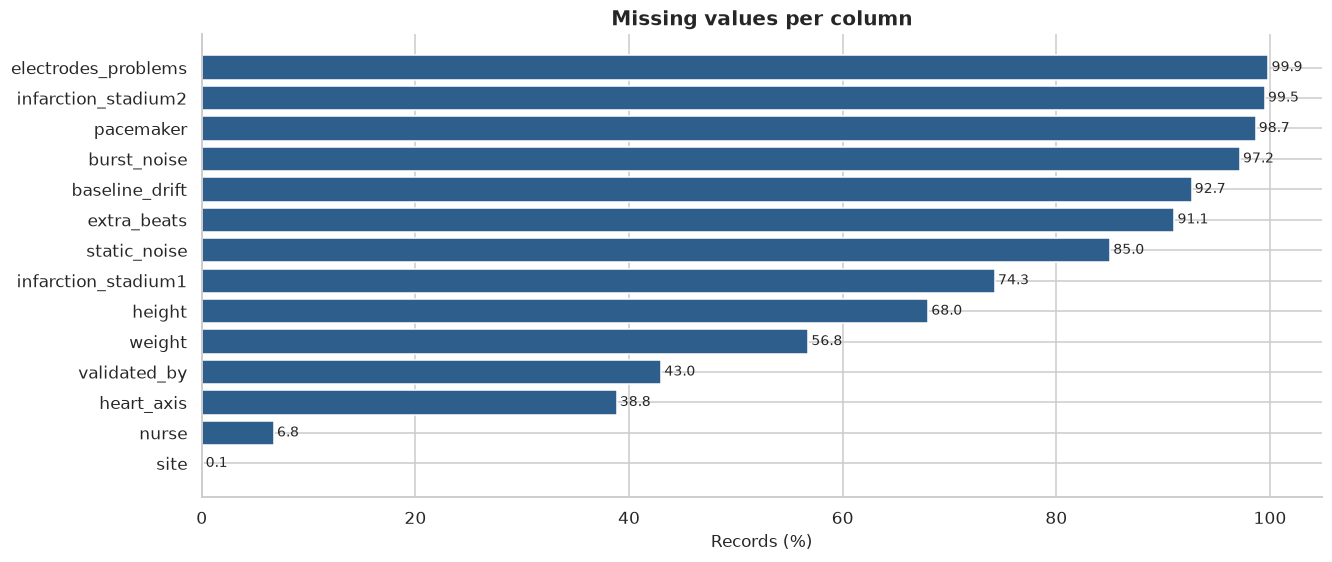

In [10]:
missing_ratio = database.isna().mean().sort_values(ascending=False)
Charts.bar(missing_ratio[missing_ratio > 0] * 100, "Missing values per column", ylabel="Records (%)", horizontal=True, value_format="%.1f")

In [11]:
database[list(MODEL_METADATA_COLUMNS)].isna().sum().to_frame("missing")

,missing
patient_id,0
age,0
sex,0
strat_fold,0


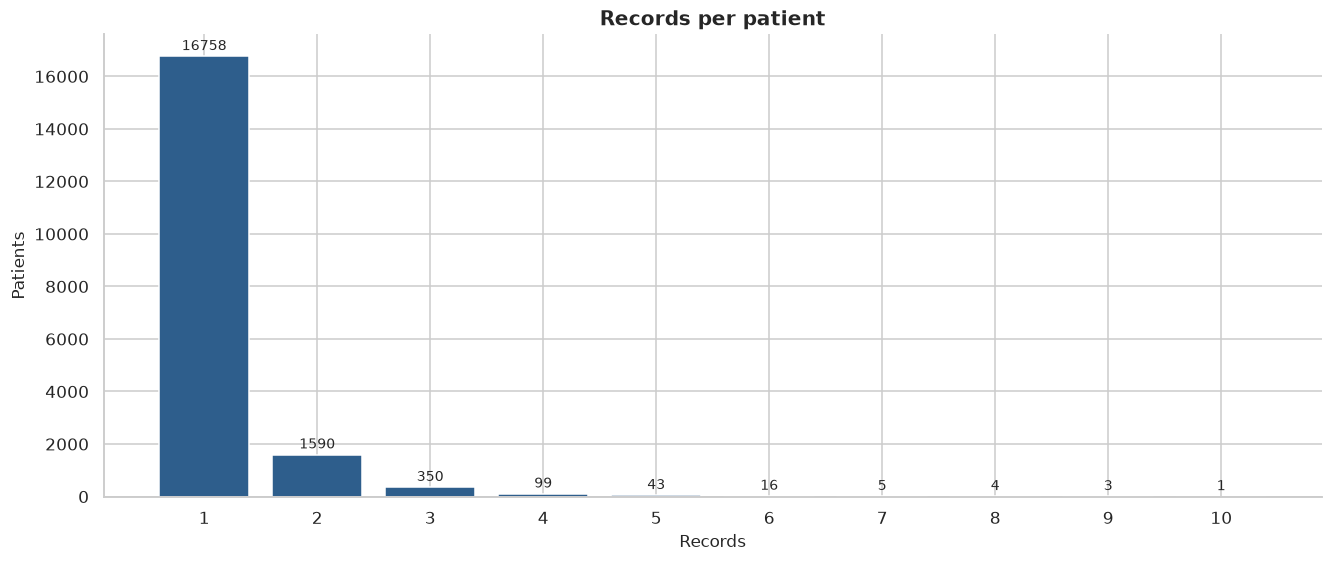

In [12]:
records_per_patient = database.groupby("patient_id").size()
Charts.bar(records_per_patient.value_counts().sort_index(), "Records per patient", xlabel="Records", ylabel="Patients")

In [13]:
pd.Series({
    "single_record_patient_ratio": (records_per_patient == 1).mean(),
    "records_from_multi_record_patients_ratio": records_per_patient[records_per_patient > 1].sum() / len(database),
    "largest_patient_group": records_per_patient.max()
}).round(4).to_frame("value")

,value
single_record_patient_ratio,0.8881
records_from_multi_record_patients_ratio,0.2312
largest_patient_group,10.0000


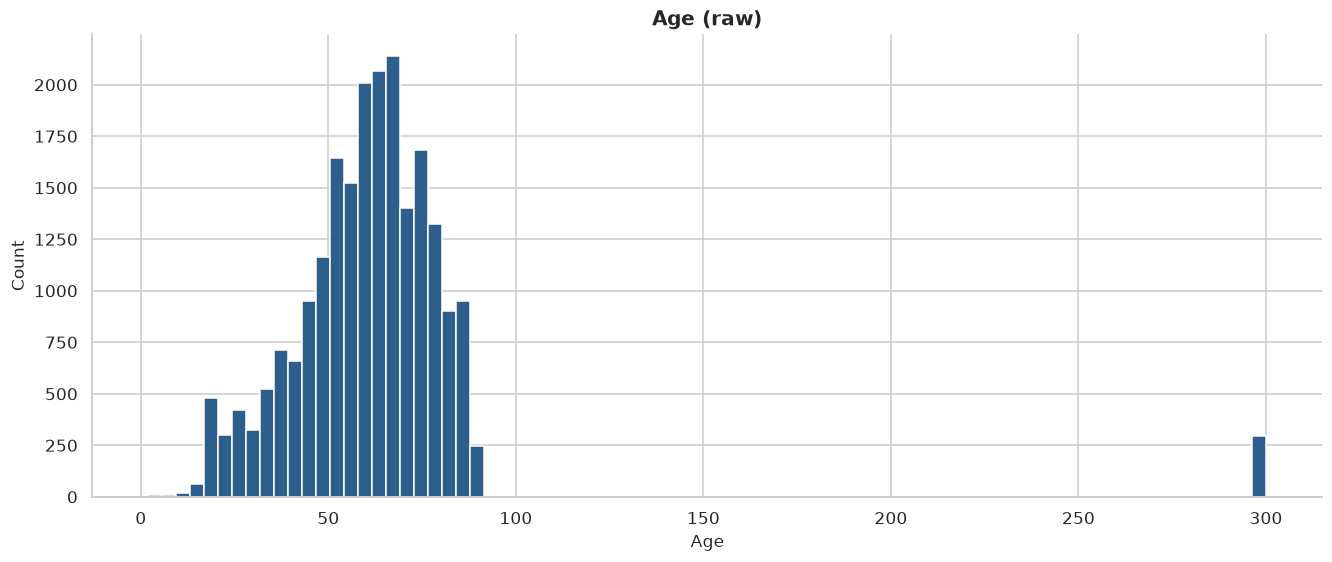

In [14]:
Charts.histogram(database["age"], "Age (raw)", "Age", bins=80)

In [15]:
anonymized_age = database["age"] > MAX_PLAUSIBLE_AGE
print(f"anonymized ages: {anonymized_age.sum()} | values: {sorted(database.loc[anonymized_age, 'age'].unique())}")
print(f"age == 0: {(database['age'] == 0).sum()} | age < 18: {(database['age'] < 18).sum()}")

anonymized ages: 293 | values: [np.float64(300.0)]
age == 0: 0 | age < 18: 133


In [16]:
database["age_over_89"] = database["age"] > MAX_PLAUSIBLE_AGE
database["age_capped"] = database["age"].where(~database["age_over_89"], CAPPED_AGE)
database["sex_label"] = database["sex"].map(SEX_LABELS)

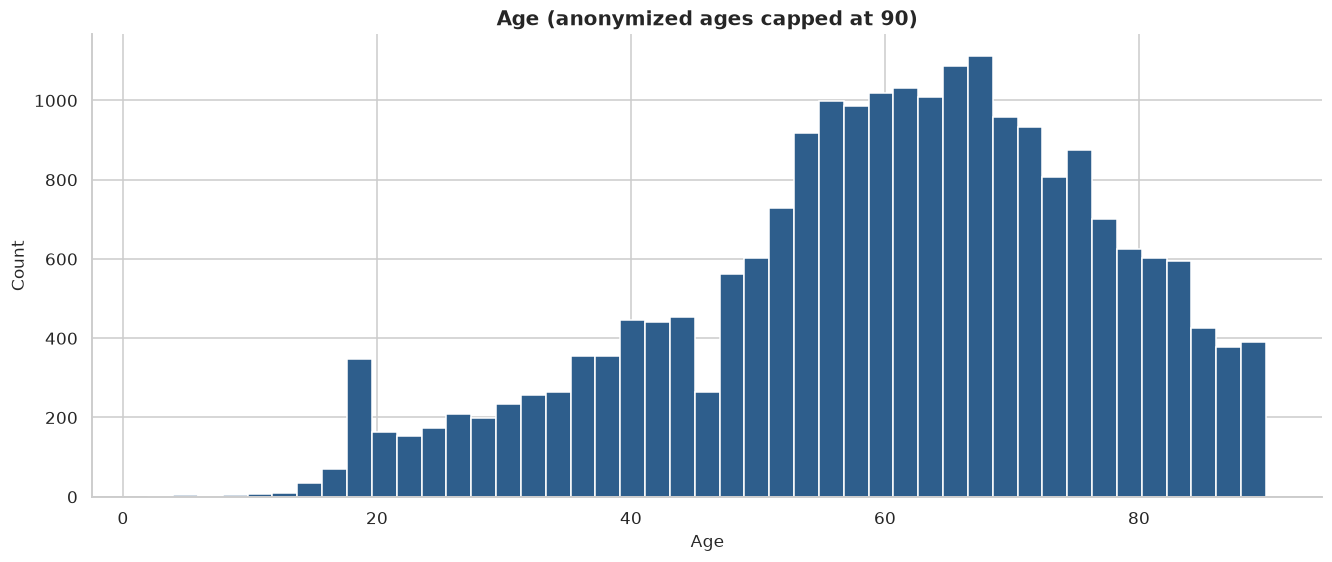

In [17]:
Charts.histogram(database["age_capped"], f"Age (anonymized ages capped at {CAPPED_AGE})", "Age", bins=45)

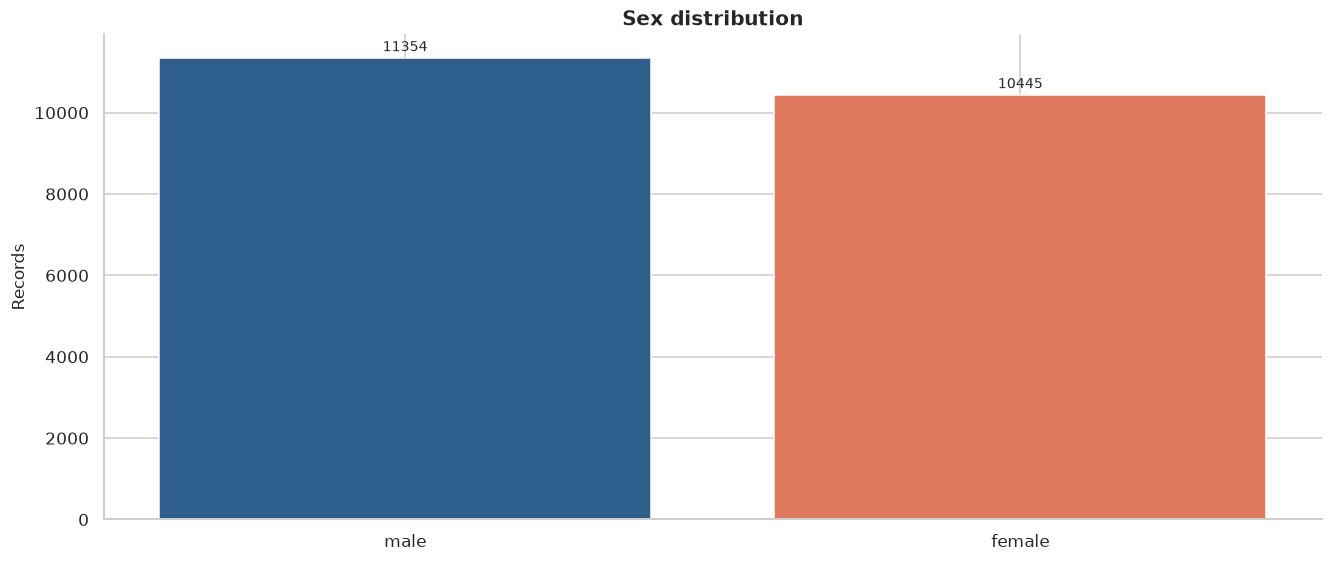

In [18]:
sex_counts = database["sex_label"].value_counts()
Charts.bar(sex_counts, "Sex distribution", ylabel="Records", color=[SEX_COLORS[label] for label in sex_counts.index])

In [19]:
body_columns = ["height", "weight"]
database[body_columns].describe().T.assign(missing_ratio=database[body_columns].isna().mean())

,count,mean,std,min,25%,50%,75%,max,missing_ratio
height,6974.0,166.702323,10.867321,6.0,160.0,166.0,174.0,209.0,0.680077
weight,9421.0,70.995223,15.878803,5.0,60.0,70.0,80.0,250.0,0.567824


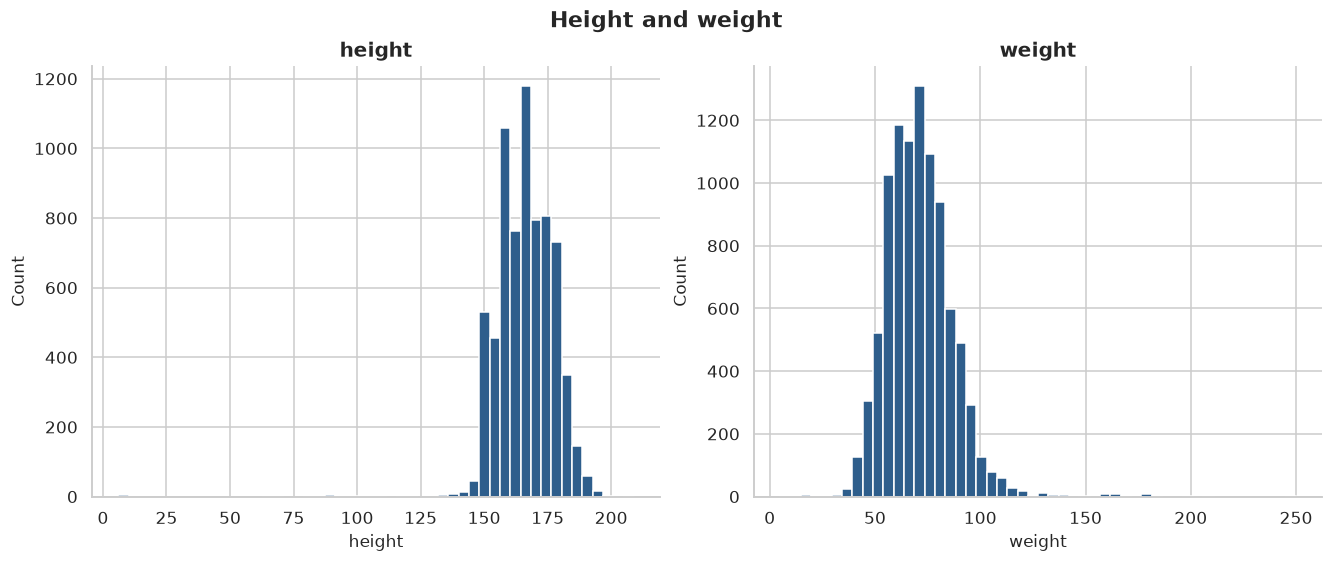

In [20]:
Charts.histogram_grid(database, ["height", "weight"], "Height and weight")

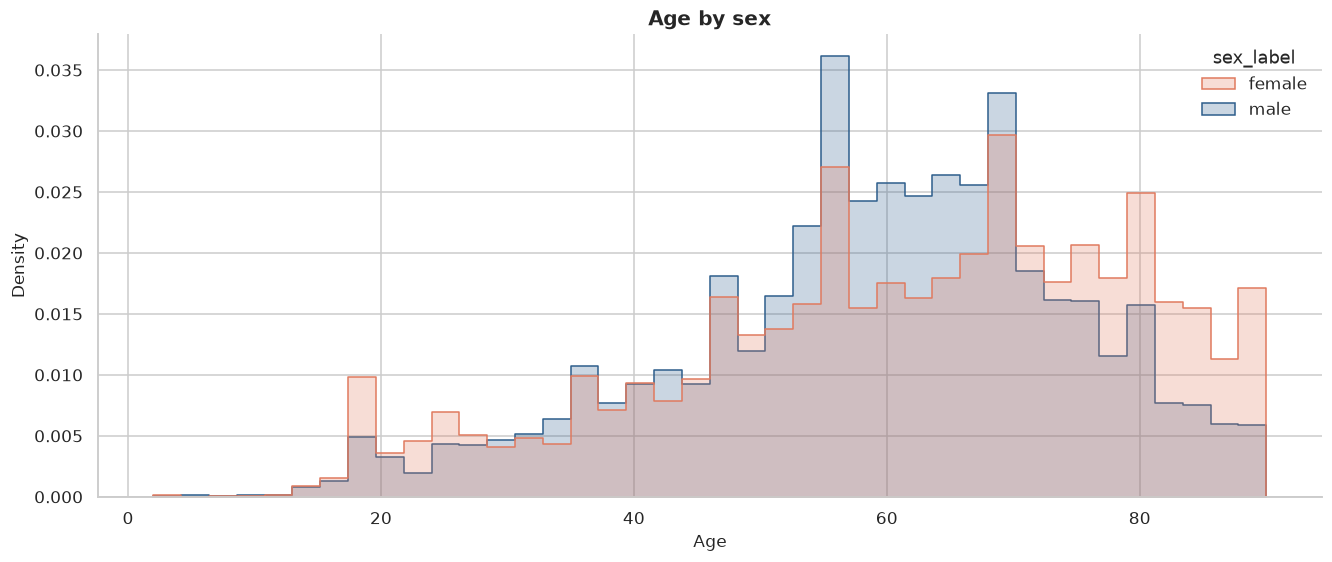

In [21]:
Charts.distribution_by_group(database, "age_capped", "sex_label", "Age by sex", "Age", SEX_COLORS)

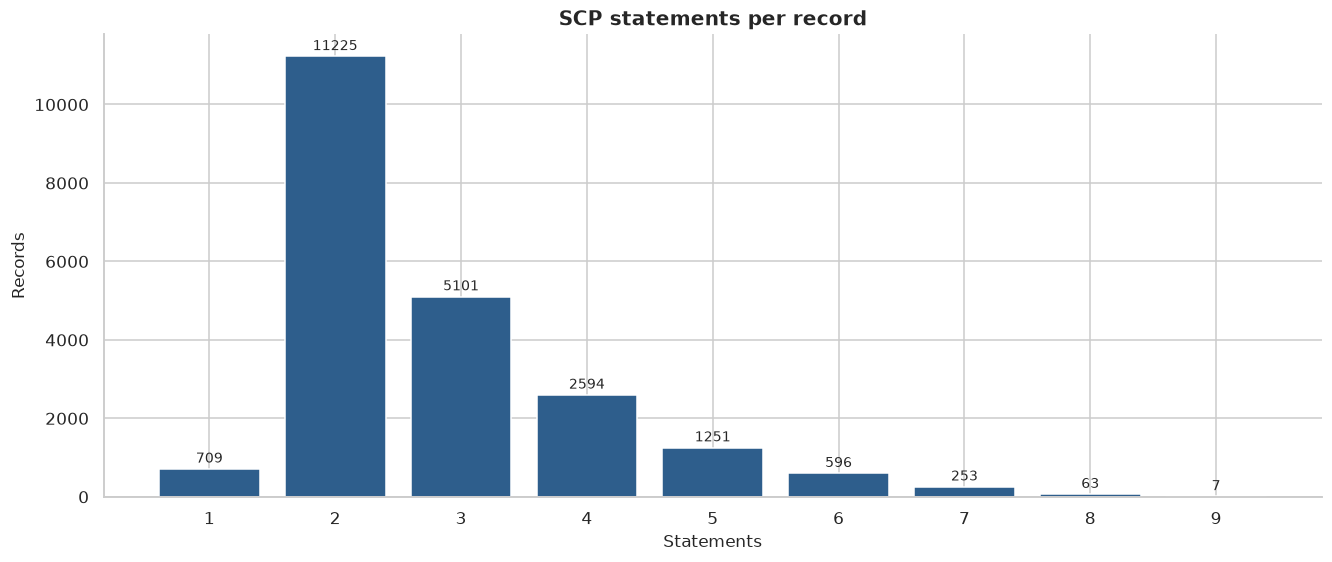

In [22]:
statements_per_record = database["scp_codes"].apply(len)
Charts.bar(statements_per_record.value_counts().sort_index(), "SCP statements per record", xlabel="Statements", ylabel="Records")

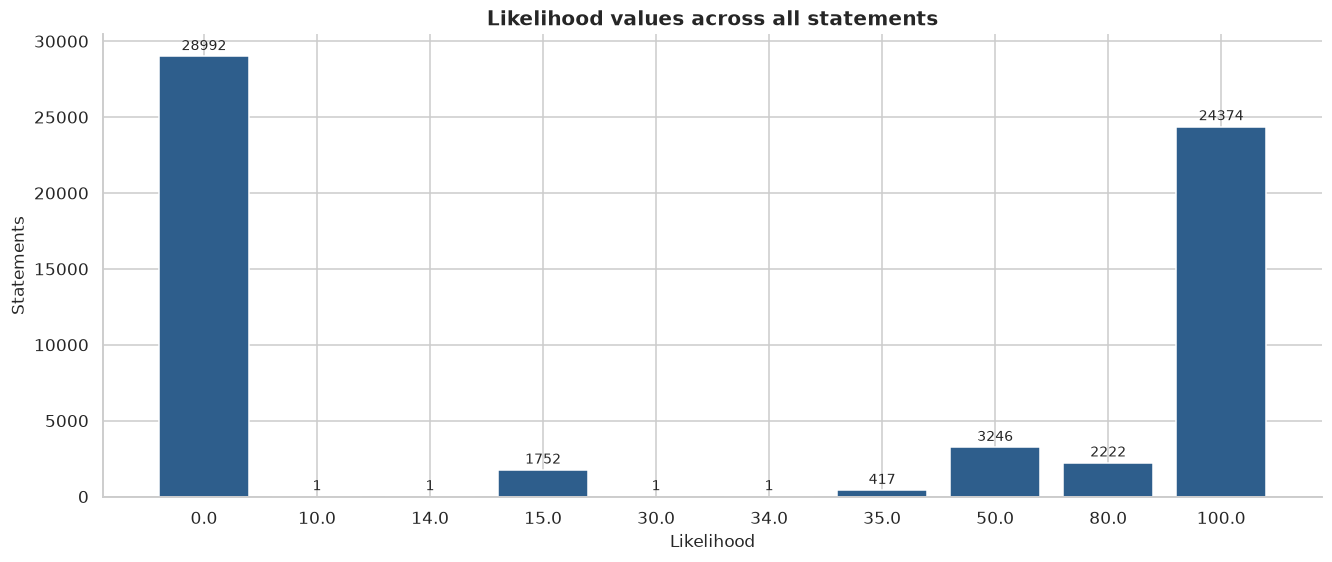

In [23]:
likelihoods = pd.Series(list(chain.from_iterable(codes.values() for codes in database["scp_codes"])))
Charts.bar(likelihoods.value_counts().sort_index(), "Likelihood values across all statements", xlabel="Likelihood", ylabel="Statements")

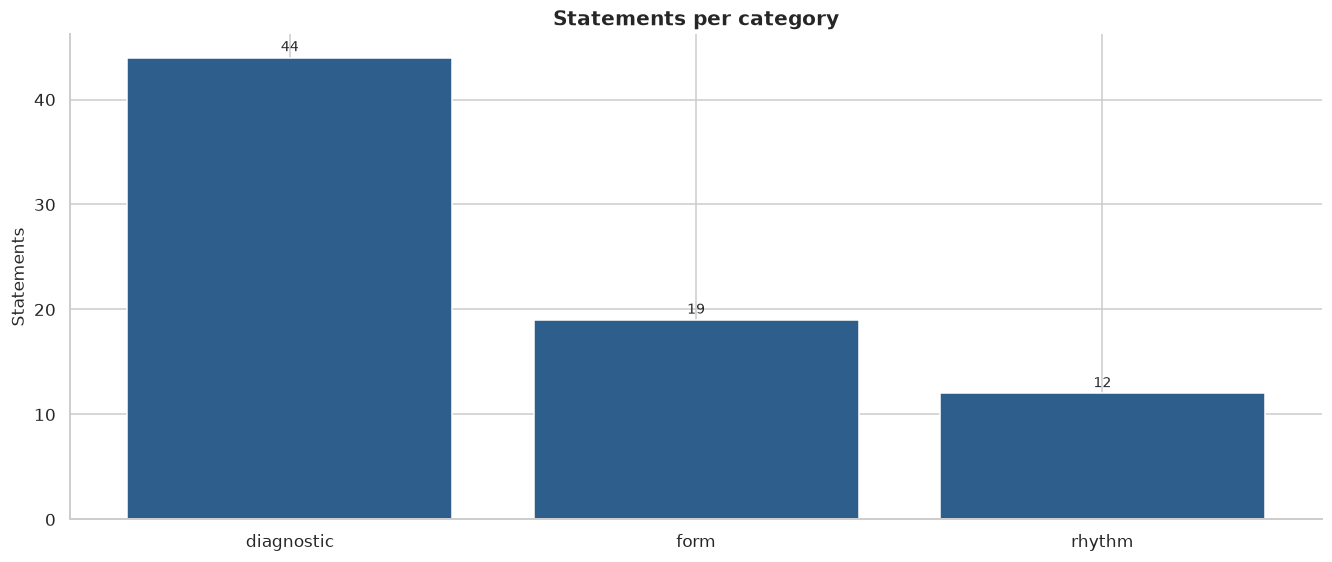

statements
diagnostic form rhythm            
1          0    0               40
0          1    0               15
           0    1               12
1          1    0                4

In [24]:
category_flags = statements[list(STATEMENT_CATEGORIES)].fillna(0).astype(int)
Charts.bar(category_flags.sum(), "Statements per category", ylabel="Statements")
category_flags.value_counts().to_frame("statements")

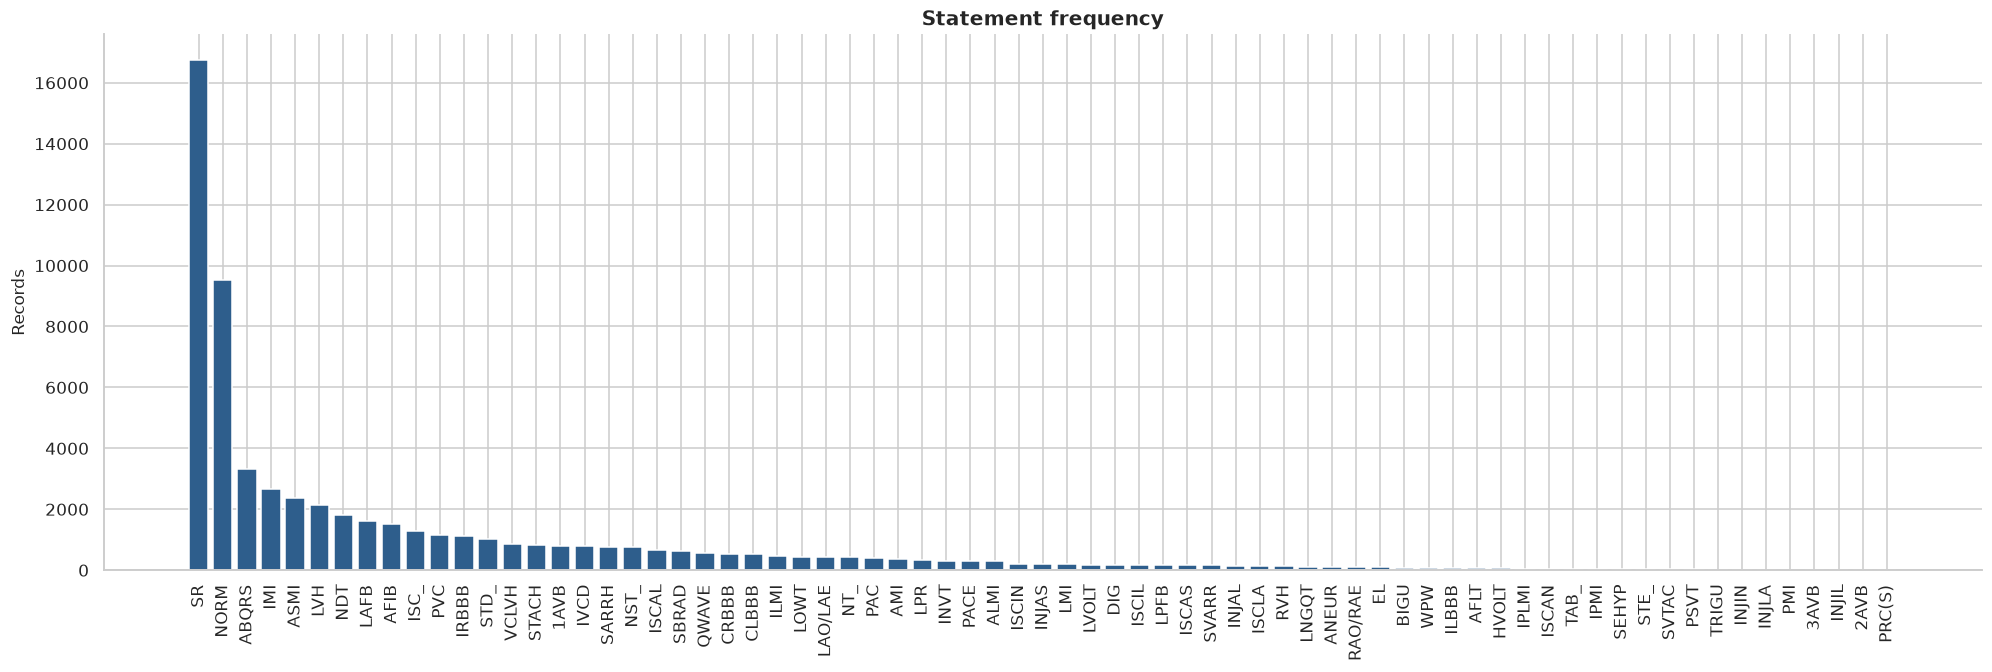

In [25]:
statement_frequency = pd.Series(Counter(chain.from_iterable(database["scp_codes"]))).sort_values(ascending=False)
Charts.bar(statement_frequency, "Statement frequency", ylabel="Records", size=WIDE_FIGURE_SIZE, rotation=90, annotate=False)

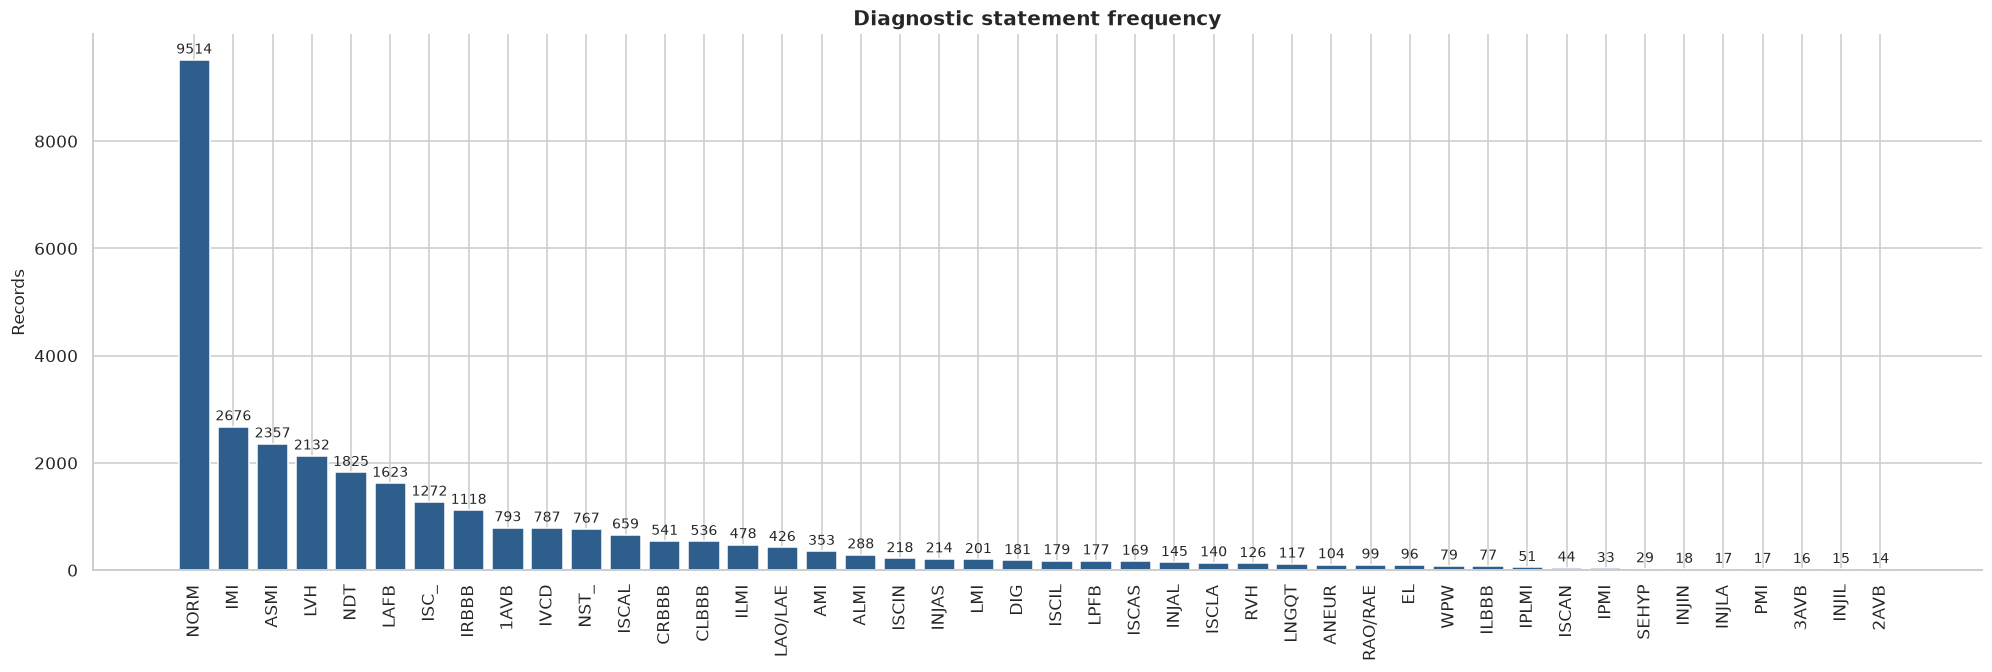

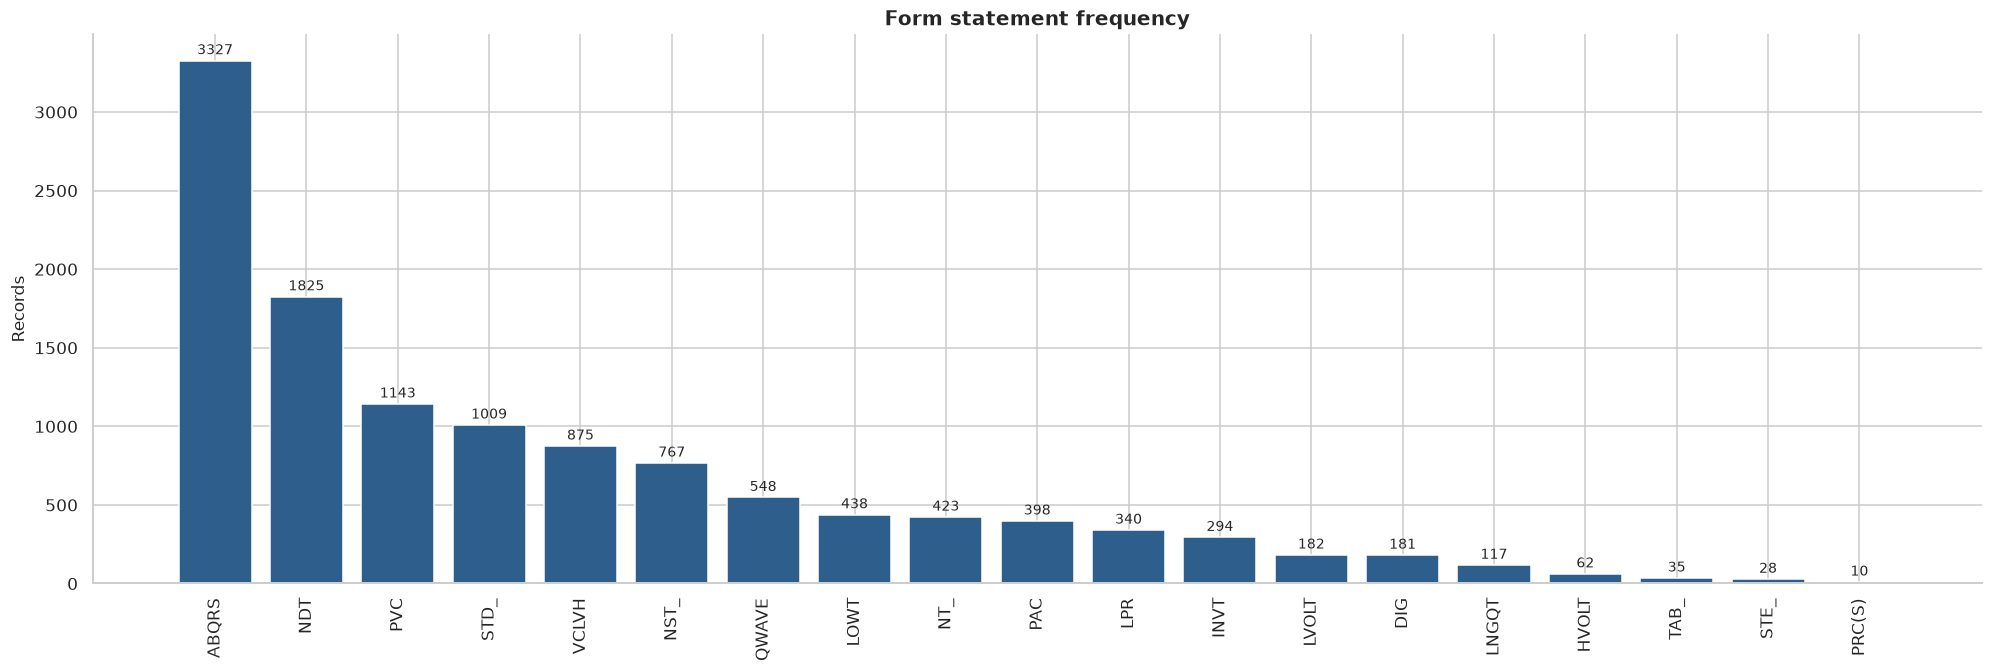

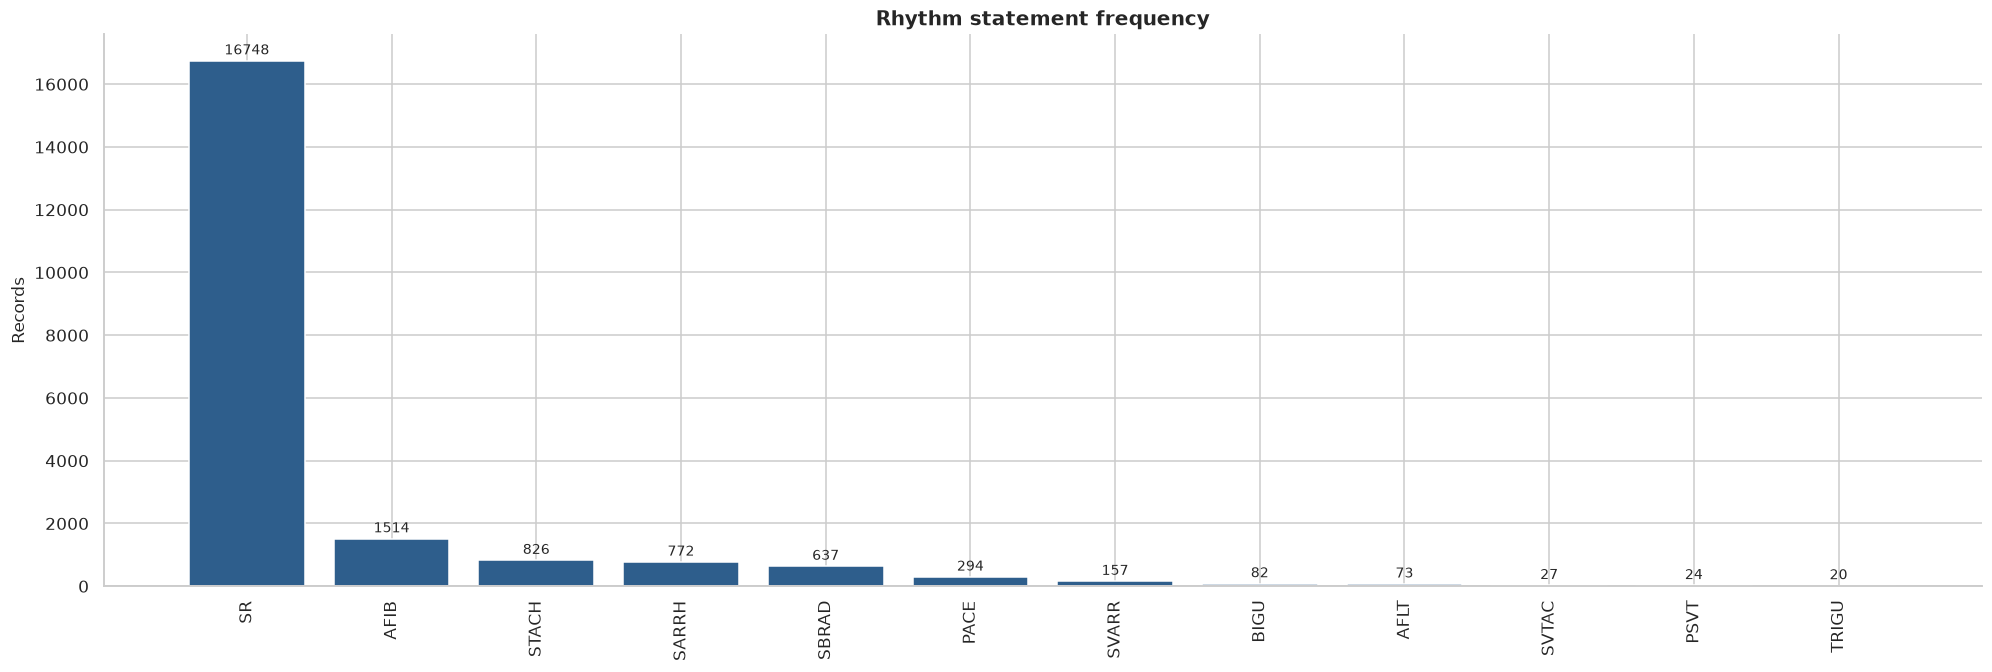

In [26]:
for category in STATEMENT_CATEGORIES:
    category_frequency = statement_frequency[statement_frequency.index.isin(hierarchy.category_members[category])]
    Charts.bar(category_frequency, f"{category.capitalize()} statement frequency", ylabel="Records", size=WIDE_FIGURE_SIZE, rotation=90)

In [27]:
database["superclasses"] = database["scp_codes"].apply(hierarchy.superclasses)
database["subclasses"] = database["scp_codes"].apply(hierarchy.subclasses)
superclass_matrix = LabelMatrix.from_lists(database["superclasses"], SUPERCLASSES)

In [28]:
pd.Series({
    "diagnostic_statements": len(hierarchy.category_members["diagnostic"]),
    "subclasses": len(hierarchy.parent_of_subclass),
    "superclasses": len(set(hierarchy.parent_of_subclass.values()))
}).to_frame("count")

,count
diagnostic_statements,44
subclasses,23
superclasses,5


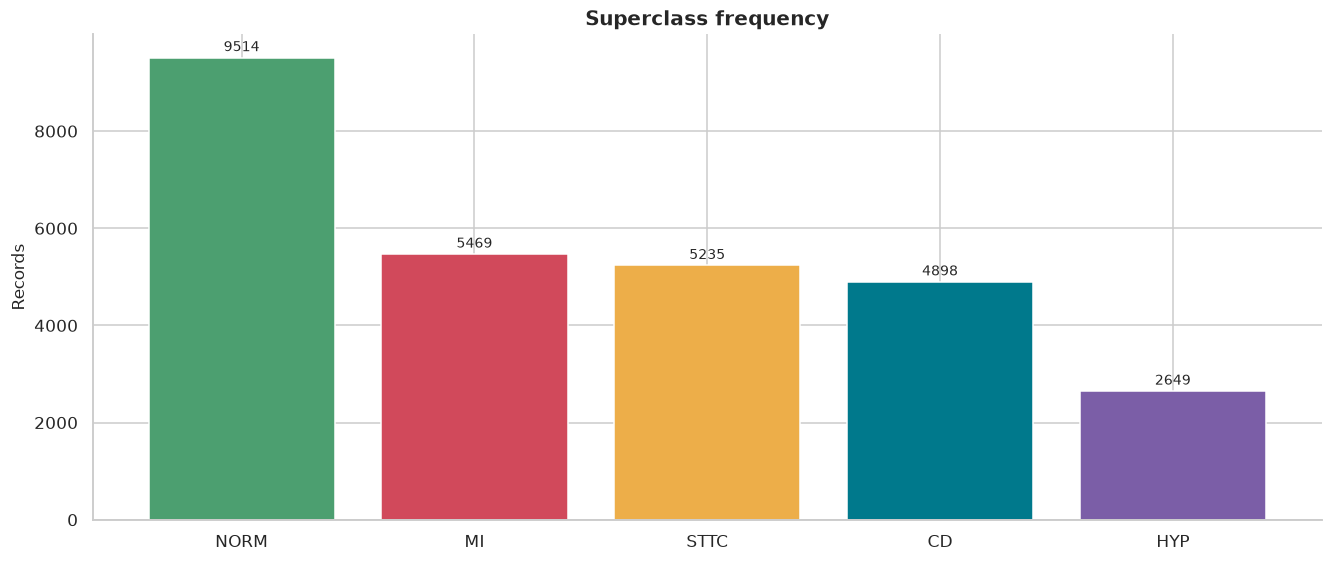

In [29]:
superclass_frequency = superclass_matrix.sum()
Charts.bar(superclass_frequency, "Superclass frequency", ylabel="Records", color=PlotTheme.class_colors(superclass_frequency.index))

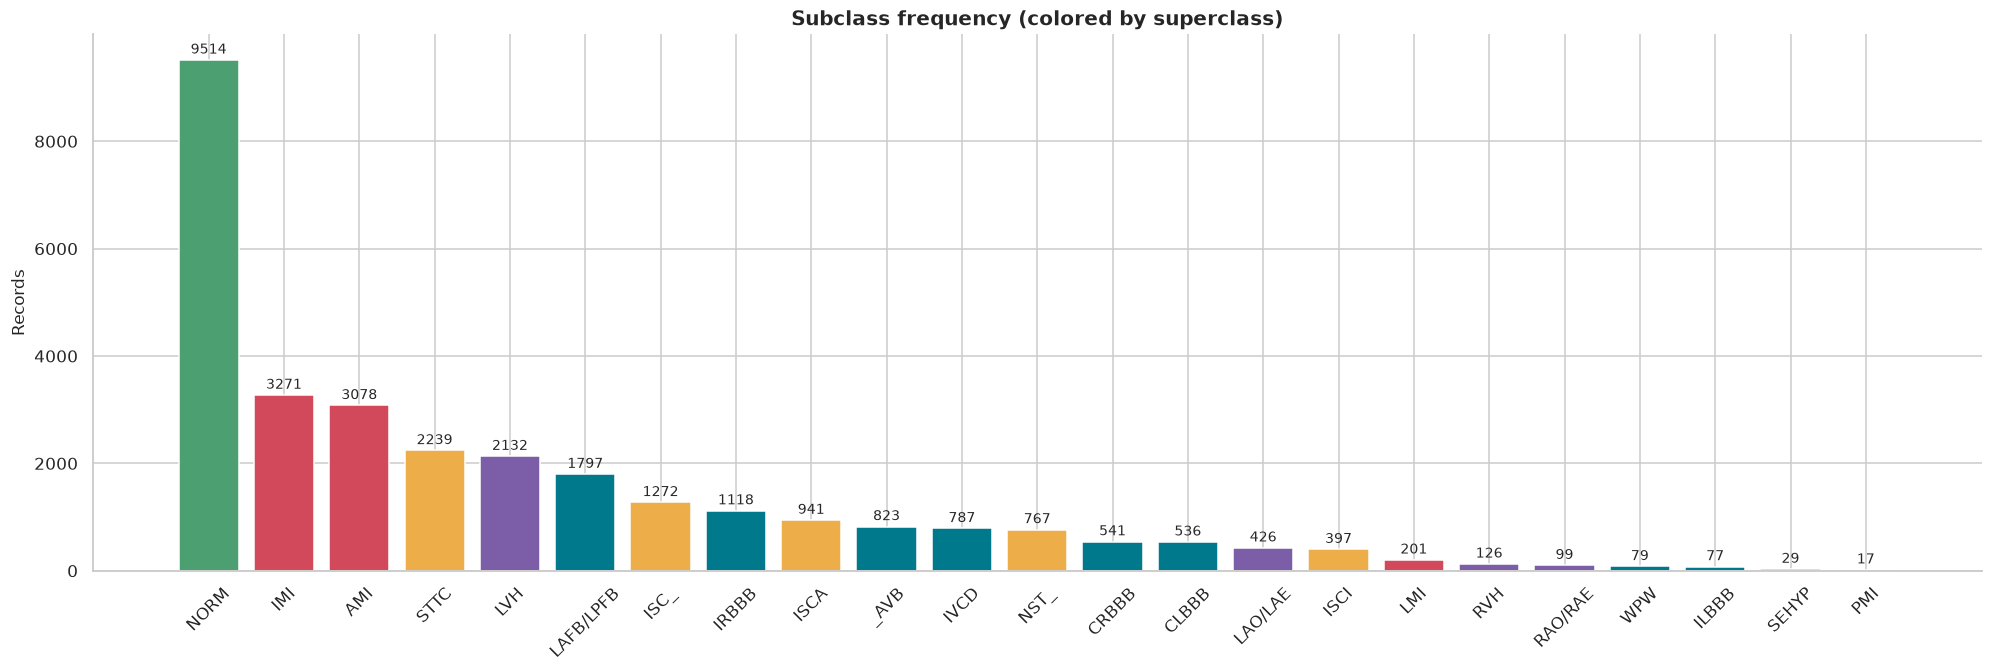

In [30]:
subclass_frequency = pd.Series(Counter(chain.from_iterable(database["subclasses"]))).sort_values(ascending=False)
subclass_colors = PlotTheme.class_colors(hierarchy.parent_of_subclass[subclass] for subclass in subclass_frequency.index)
Charts.bar(subclass_frequency, "Subclass frequency (colored by superclass)", ylabel="Records", color=subclass_colors, size=WIDE_FIGURE_SIZE, rotation=45)

records without a diagnostic superclass: 411 (1.89%)


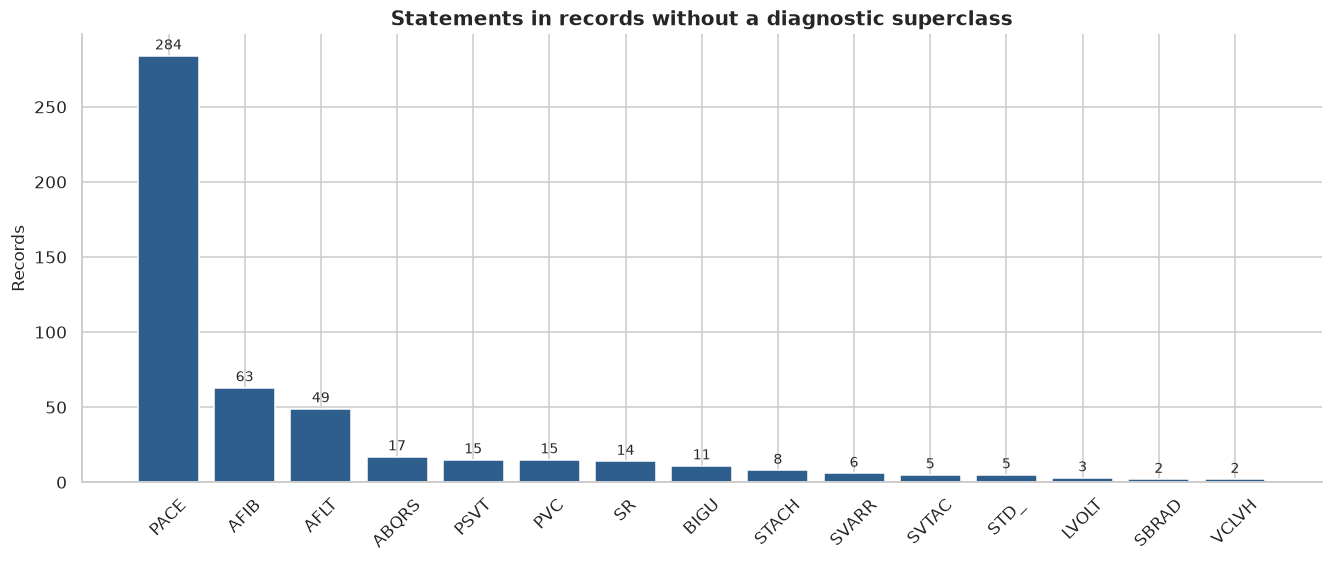

In [31]:
without_superclass = database["superclasses"].str.len() == 0
print(f"records without a diagnostic superclass: {without_superclass.sum()} ({without_superclass.mean():.2%})")
codes_without_superclass = pd.Series(Counter(chain.from_iterable(database.loc[without_superclass, "scp_codes"]))).sort_values(ascending=False)
Charts.bar(codes_without_superclass.head(TOP_CATEGORY_COUNT), "Statements in records without a diagnostic superclass", ylabel="Records", rotation=45)

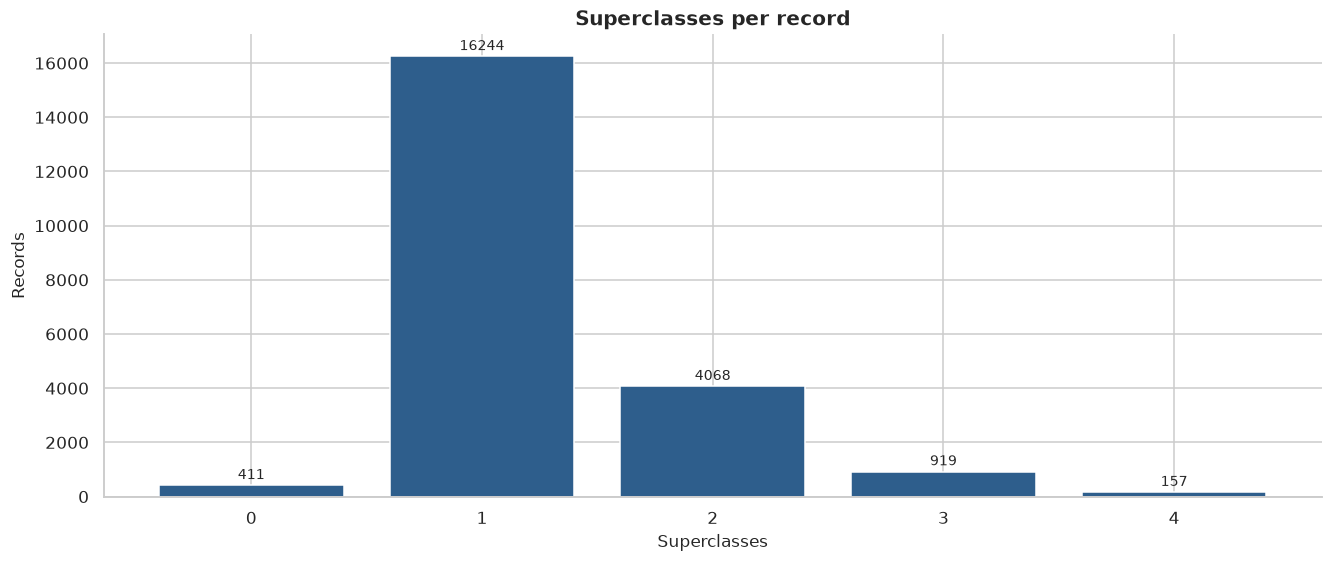

In [32]:
superclass_cardinality = database["superclasses"].str.len()
Charts.bar(superclass_cardinality.value_counts().sort_index(), "Superclasses per record", xlabel="Superclasses", ylabel="Records")

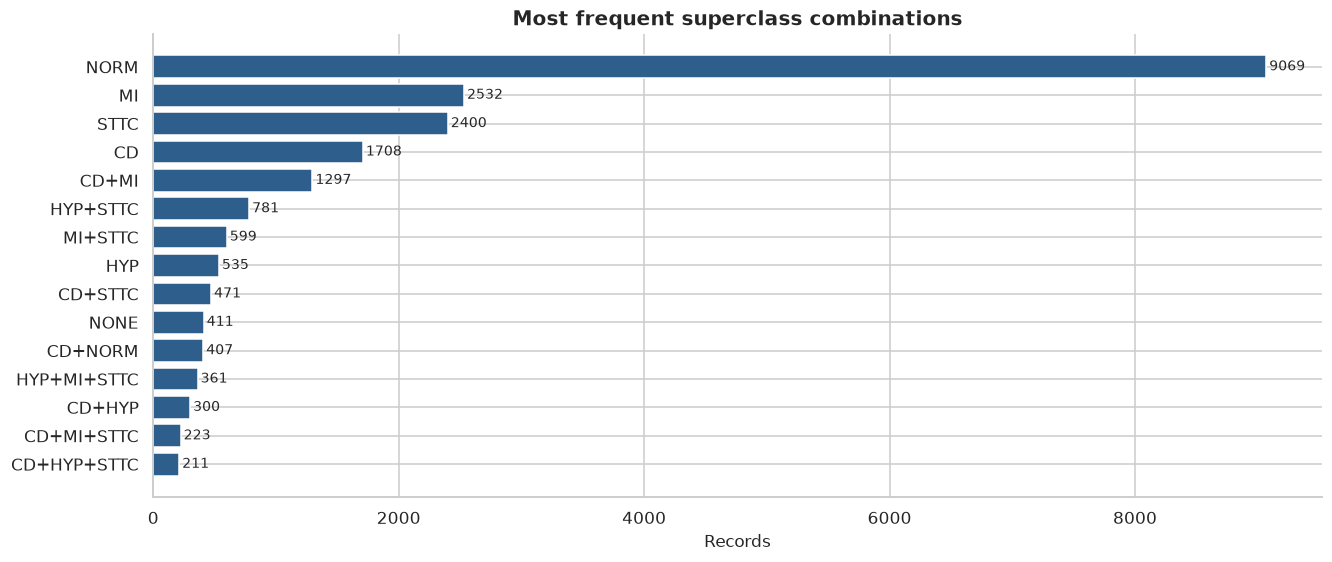

In [33]:
combination_counts = database["superclasses"].apply(LabelMatrix.combination_key).value_counts()
Charts.bar(combination_counts.head(TOP_CATEGORY_COUNT), "Most frequent superclass combinations", ylabel="Records", horizontal=True)

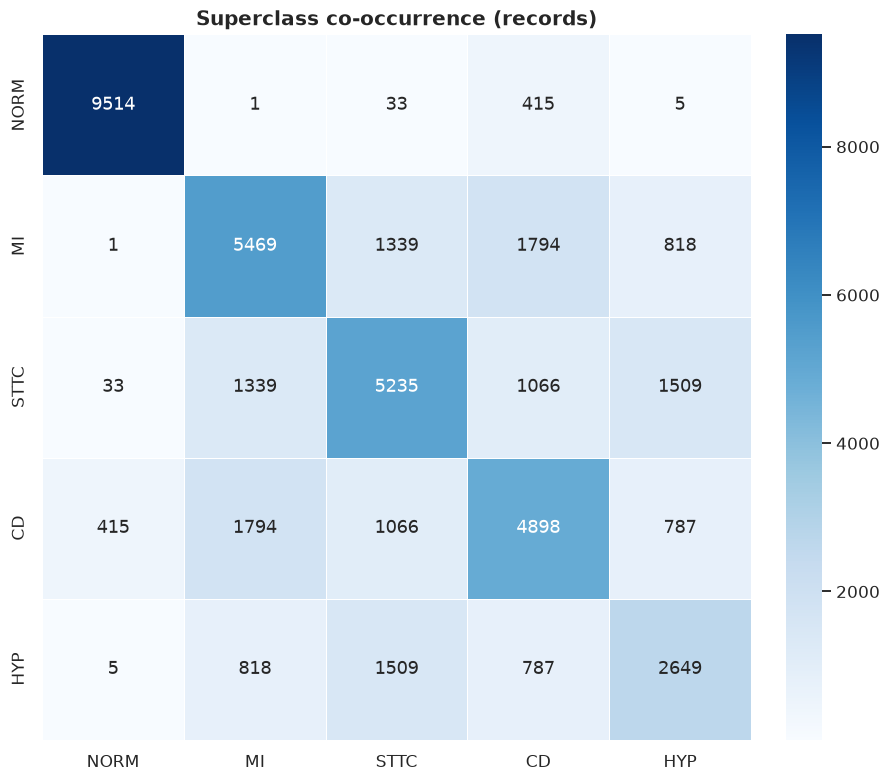

In [34]:
co_occurrence = LabelMatrix.co_occurrence(superclass_matrix)
Charts.heatmap(co_occurrence, "Superclass co-occurrence (records)")

NORM records with another superclass: 445


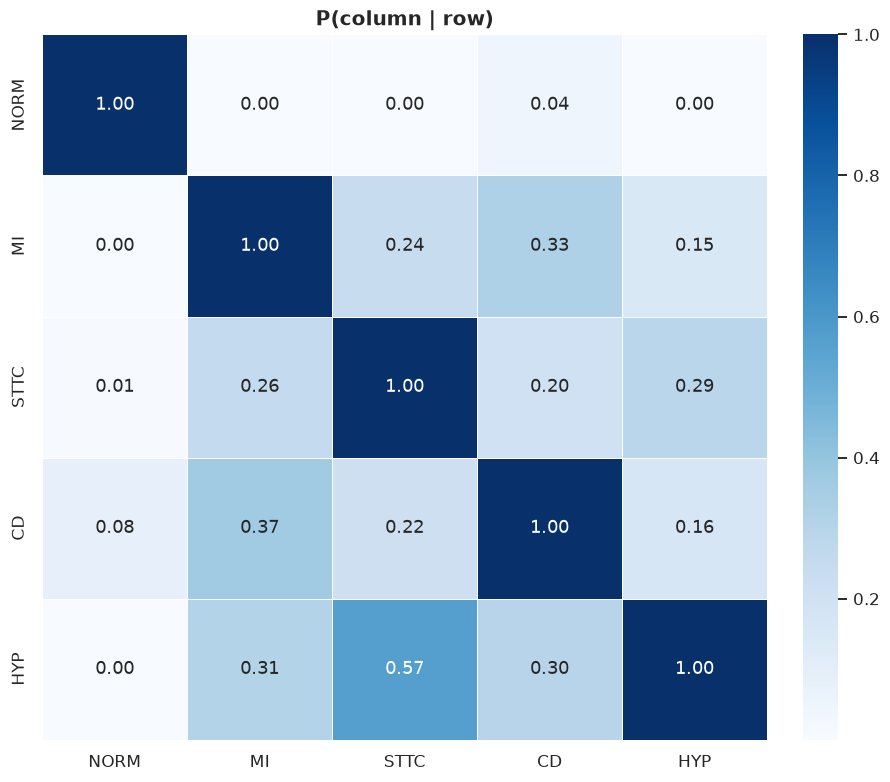

In [35]:
conditional_co_occurrence = co_occurrence.div(np.diag(co_occurrence), axis=0)
norm_with_others = superclass_matrix["NORM"].eq(1) & superclass_matrix.drop(columns="NORM").sum(axis=1).gt(0)
print(f"NORM records with another superclass: {norm_with_others.sum()}")
Charts.heatmap(conditional_co_occurrence, "P(column | row)", value_format=".2f")

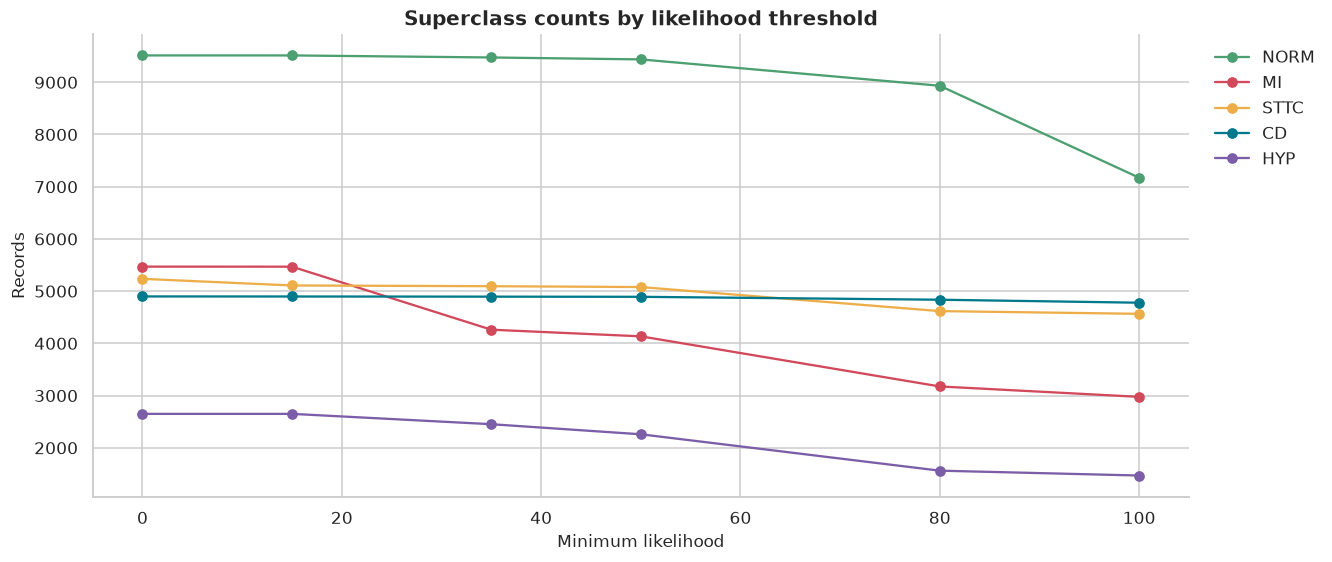

In [36]:
threshold_counts = pd.DataFrame({
    threshold: LabelMatrix.from_lists(database["scp_codes"].apply(hierarchy.superclasses, threshold=threshold), SUPERCLASSES).sum()
    for threshold in LIKELIHOOD_THRESHOLDS
}).T
Charts.lines(threshold_counts, "Superclass counts by likelihood threshold", "Minimum likelihood", "Records", colors=PlotTheme.class_colors(SUPERCLASSES))

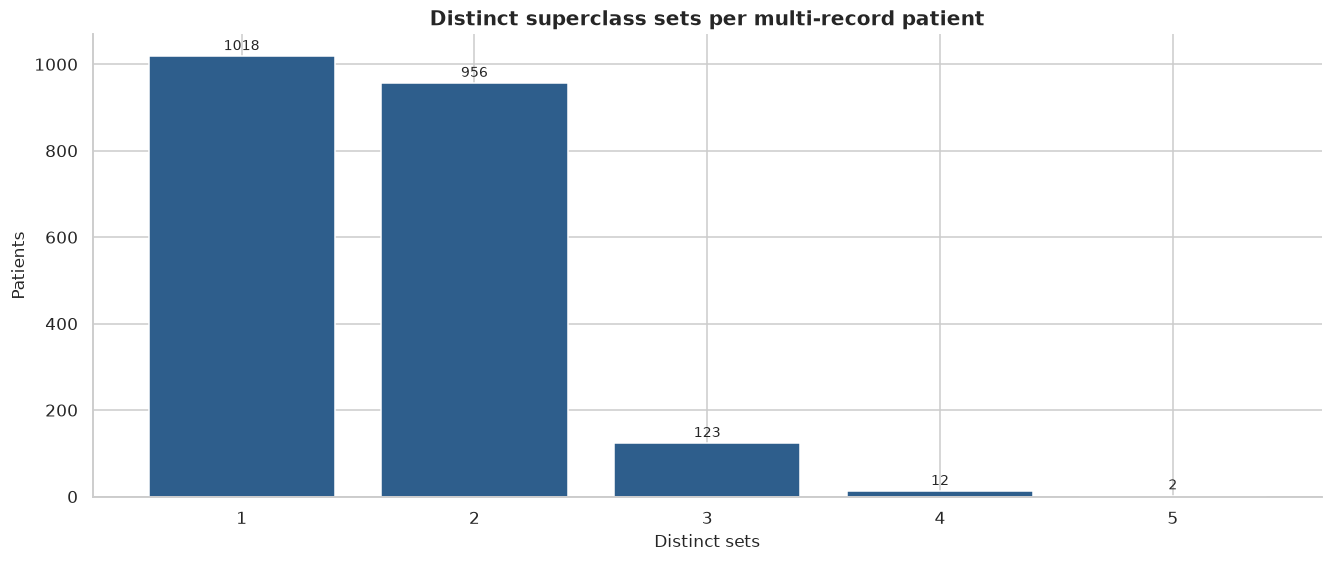

In [37]:
multi_record_mask = database["patient_id"].map(records_per_patient) > 1
distinct_label_sets = database[multi_record_mask].groupby("patient_id")["superclasses"].agg(lambda label_sets: len({tuple(labels) for labels in label_sets}))
Charts.bar(distinct_label_sets.value_counts().sort_index(), "Distinct superclass sets per multi-record patient", xlabel="Distinct sets", ylabel="Patients")

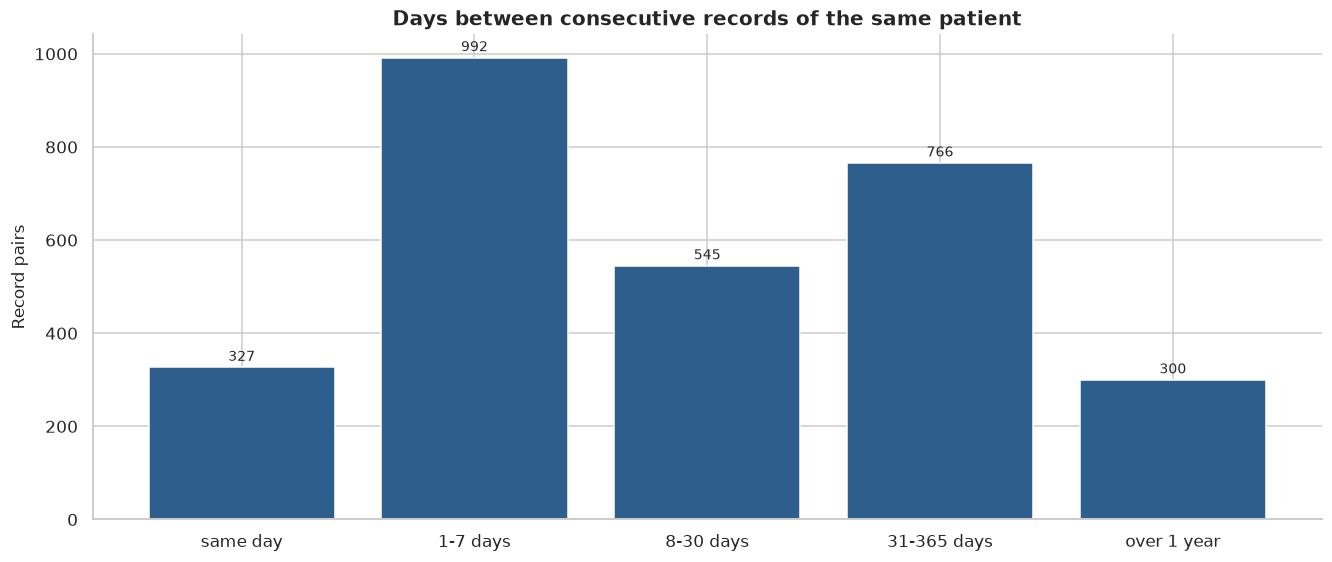

In [38]:
record_order = database.loc[multi_record_mask, ["patient_id", "recording_date"]].assign(recording_time=lambda frame: pd.to_datetime(frame["recording_date"])).sort_values(["patient_id", "recording_time"])
gap_days = record_order.groupby("patient_id")["recording_time"].diff().dt.days.dropna()
gap_buckets = pd.cut(gap_days, bins=list(GAP_DAY_EDGES), labels=list(GAP_DAY_LABELS)).value_counts().reindex(list(GAP_DAY_LABELS))
Charts.bar(gap_buckets, "Days between consecutive records of the same patient", ylabel="Record pairs")

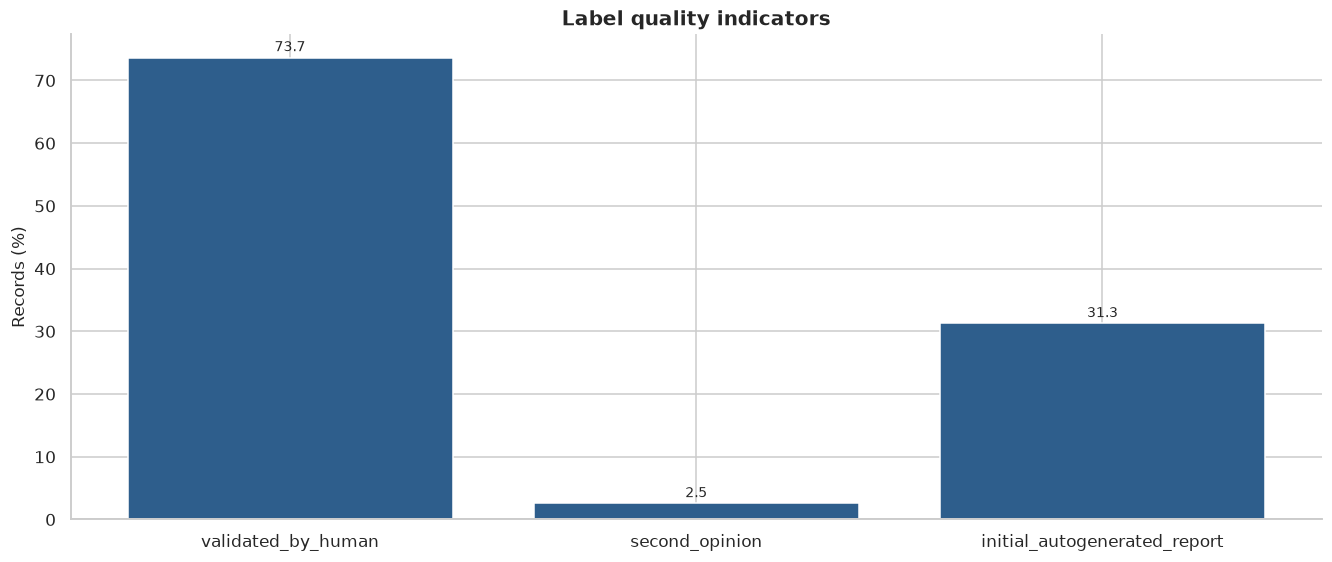

In [39]:
label_quality_rates = database[list(LABEL_QUALITY_COLUMNS)].mean()
Charts.bar(label_quality_rates * 100, "Label quality indicators", ylabel="Records (%)", value_format="%.1f")

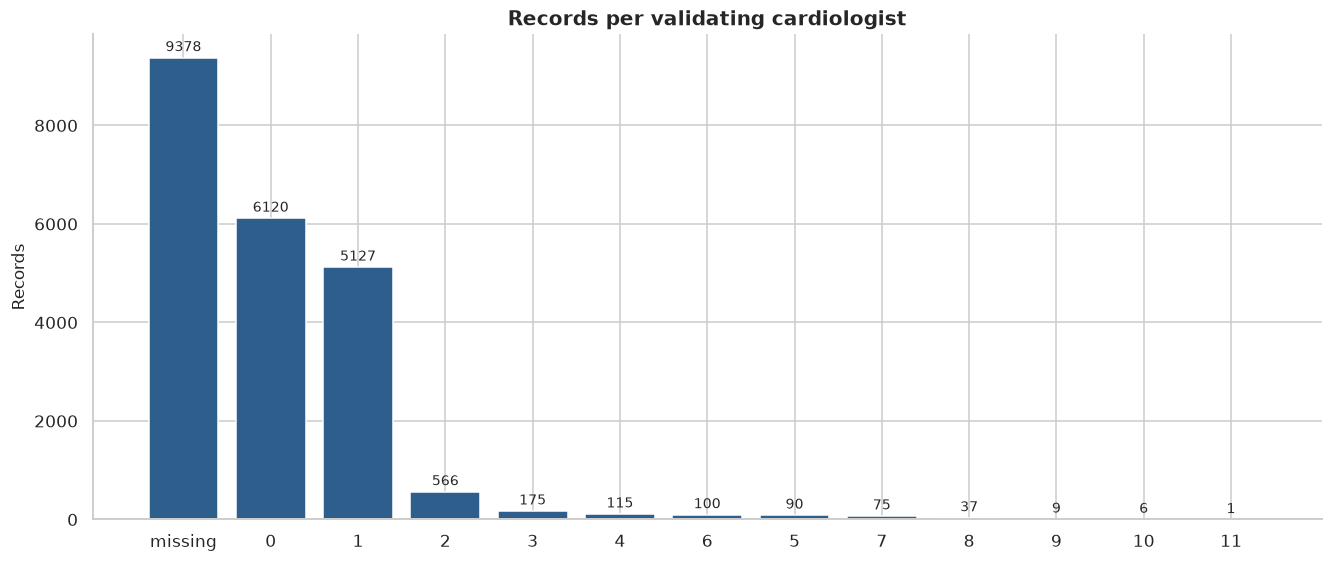

In [40]:
validator_counts = database["validated_by"].map(lambda validator: "missing" if pd.isna(validator) else str(int(validator))).value_counts()
Charts.bar(validator_counts, "Records per validating cardiologist", ylabel="Records")

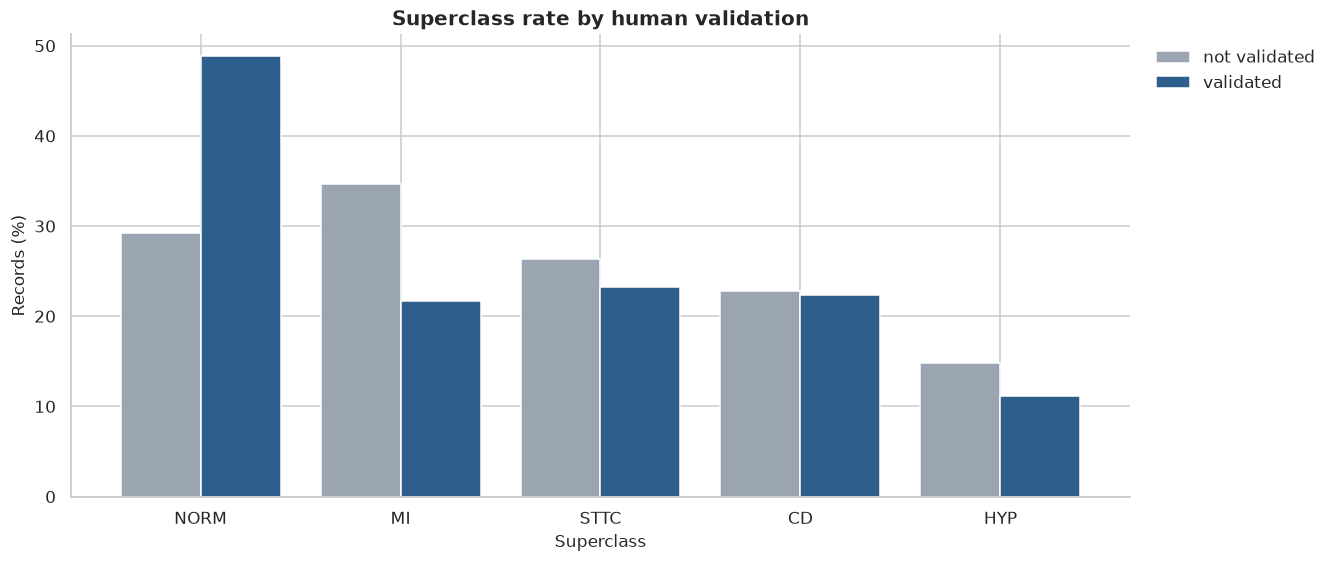

In [41]:
class_rate_by_validation = superclass_matrix.groupby(database["validated_by_human"]).mean().T.rename(columns={False: "not validated", True: "validated"})
Charts.grouped_bar(class_rate_by_validation * 100, "Superclass rate by human validation", "Superclass", "Records (%)", colors=[NEUTRAL_COLOR, PRIMARY_COLOR])

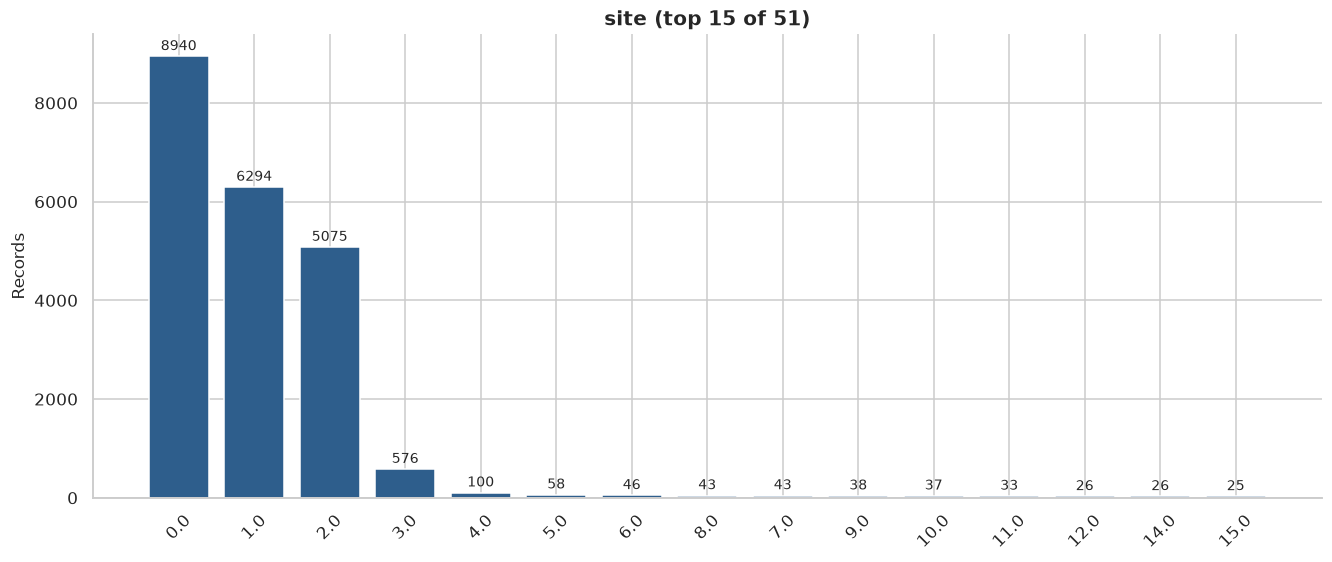

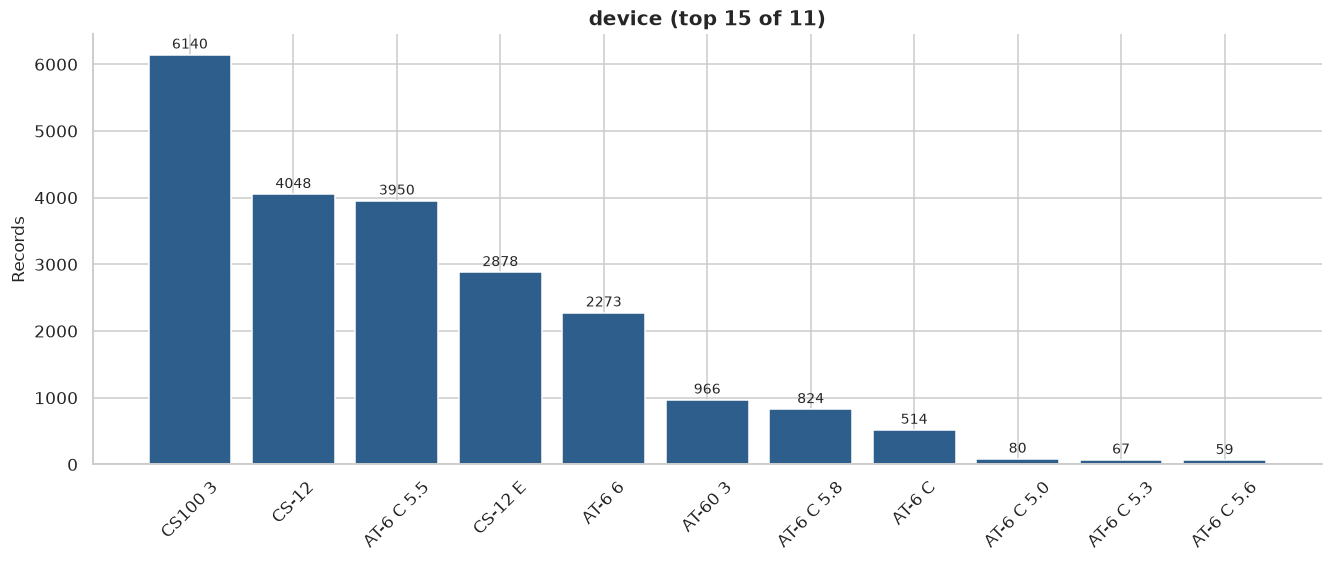

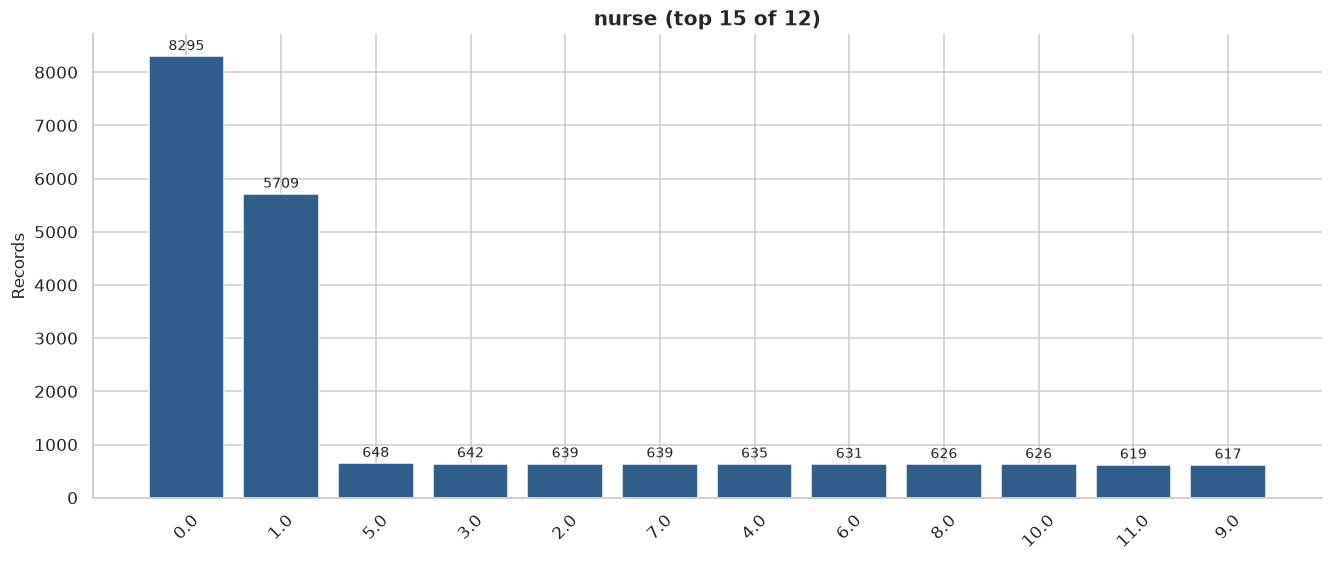

In [42]:
for column in ACQUISITION_COLUMNS:
    counts = database[column].astype(str).value_counts()
    Charts.bar(counts.head(TOP_CATEGORY_COUNT), f"{column} (top {TOP_CATEGORY_COUNT} of {len(counts)})", ylabel="Records", rotation=45)

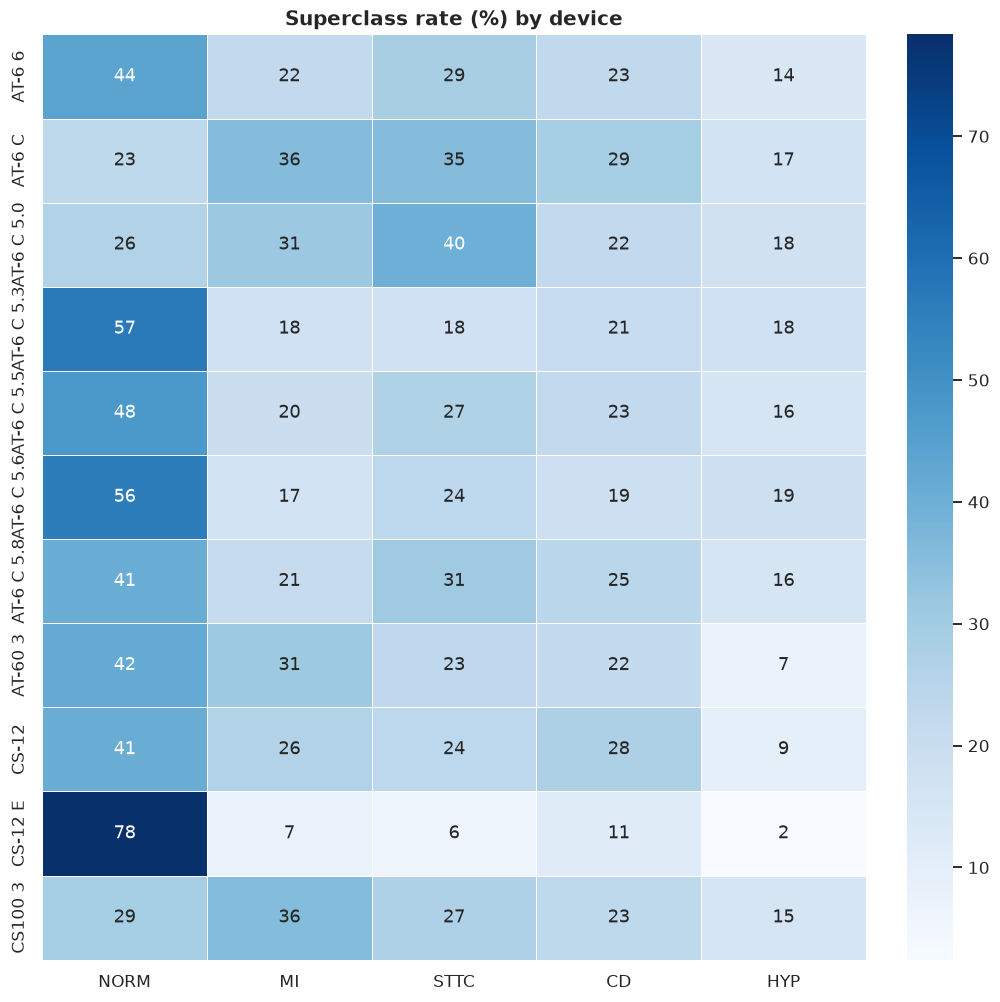

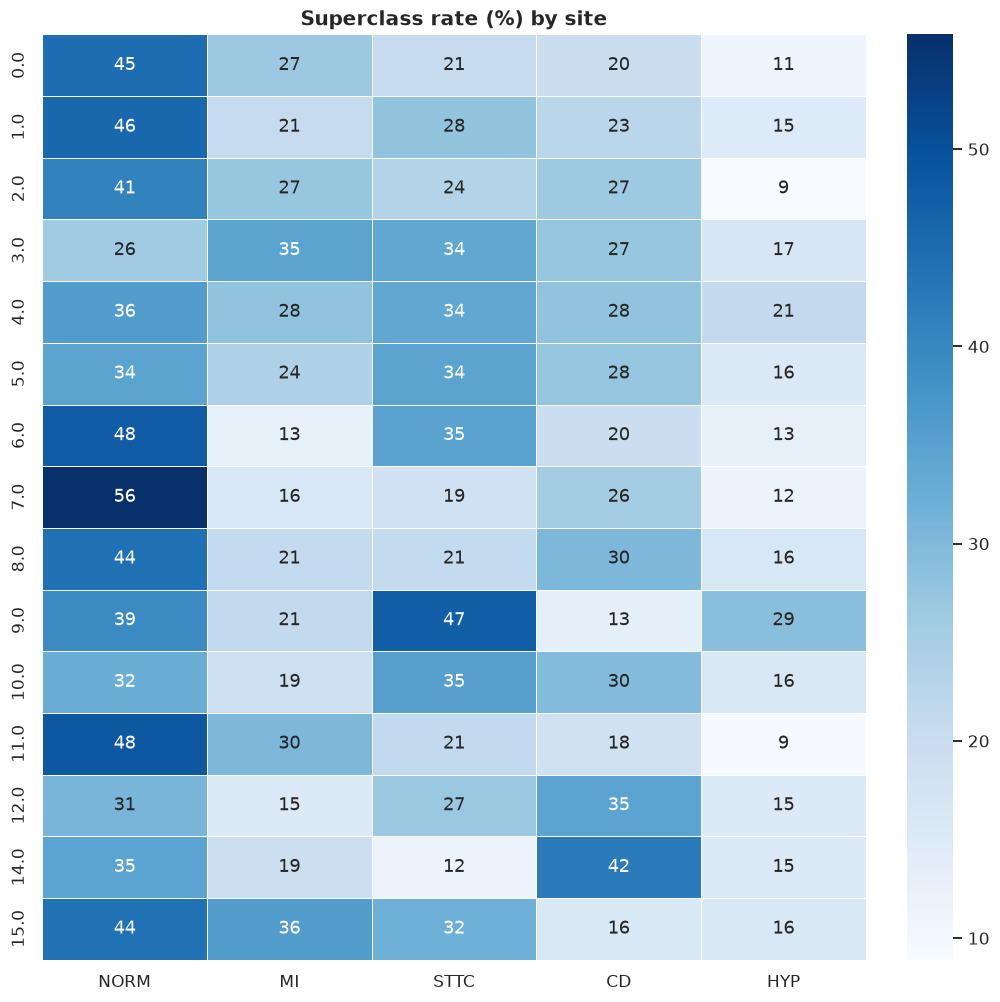

In [43]:
for column in ("device", "site"):
    in_top = database[column].isin(database[column].value_counts().head(TOP_CATEGORY_COUNT).index)
    class_rate = superclass_matrix[in_top].groupby(database.loc[in_top, column]).mean()
    Charts.heatmap(class_rate * 100, f"Superclass rate (%) by {column}", value_format=".0f", size=(9, 9))

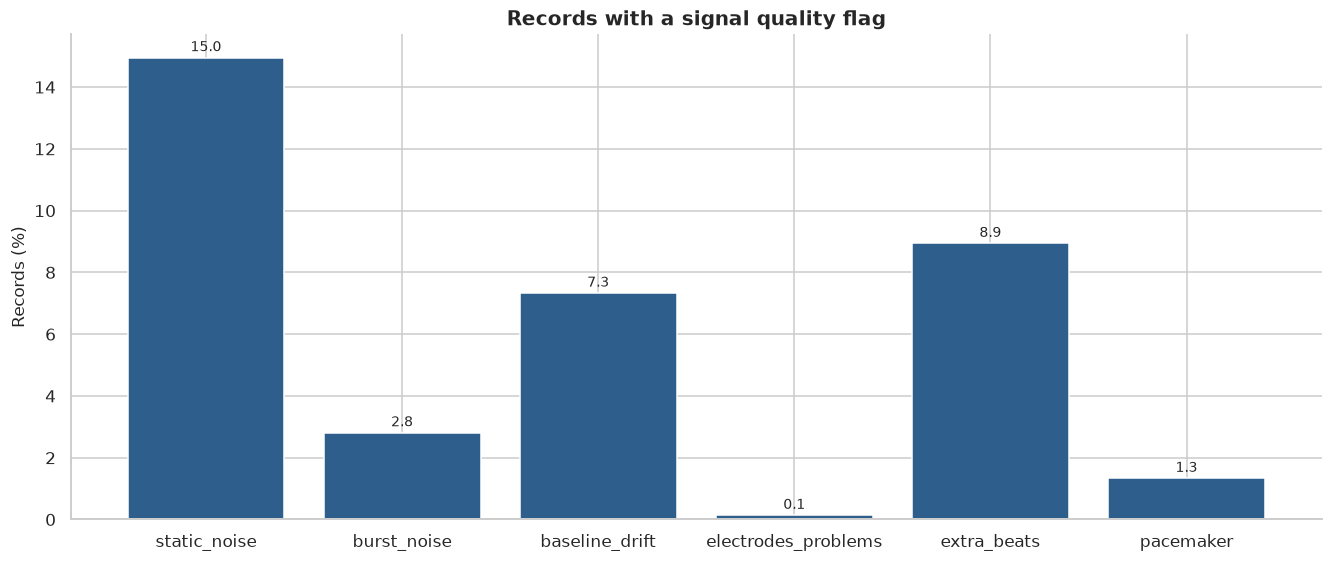

In [44]:
quality_flags = database[list(SIGNAL_QUALITY_COLUMNS)].notna().astype(int)
Charts.bar(quality_flags.mean() * 100, "Records with a signal quality flag", ylabel="Records (%)", value_format="%.1f")

In [45]:
for column in SIGNAL_QUALITY_COLUMNS:
    display(database[column].value_counts().head(TOP_CATEGORY_COUNT).to_frame(f"{column} ({database[column].nunique()} unique)"))

,static_noise (124 unique)
static_noise,
", I-AVR,",953
", I-AVF,",919
", alles,",522
", I-V1,",156
", I-V2,",144
", I-AVL,",91
", mittel,",70
", leicht,",42
", stark,",25


,burst_noise (103 unique)
burst_noise,
alles,140
I-AVF,47
V1,46
"V1,V2",28
I-AVR,24
V2,22
I-V1,21
I-V2,20
v3,17


,baseline_drift (317 unique)
baseline_drift,
", V6",221
", V1",94
", II-AVF",60
", V3",59
", V2",58
", V5,V6",57
", alles",55
", I-AVF",47
", V5",46


,electrodes_problems (14 unique)
electrodes_problems,
V6,8
V4,5
V1,4
V1???,2
V5,2
V3,1
"V5,V6",1
Kontaktprobleme aVL ???,1
I???,1


,extra_beats (128 unique)
extra_beats,
1ES,405
SVES,381
2ES,179
VES,159
"VES1,alles",151
3ES,80
"VES2,alles",70
"1,alles",61
ES,42


,pacemaker (4 unique)
pacemaker,
"ja, pacemaker",285
"ja, nan",3
"PACE????, nan",2
"?, nan",1


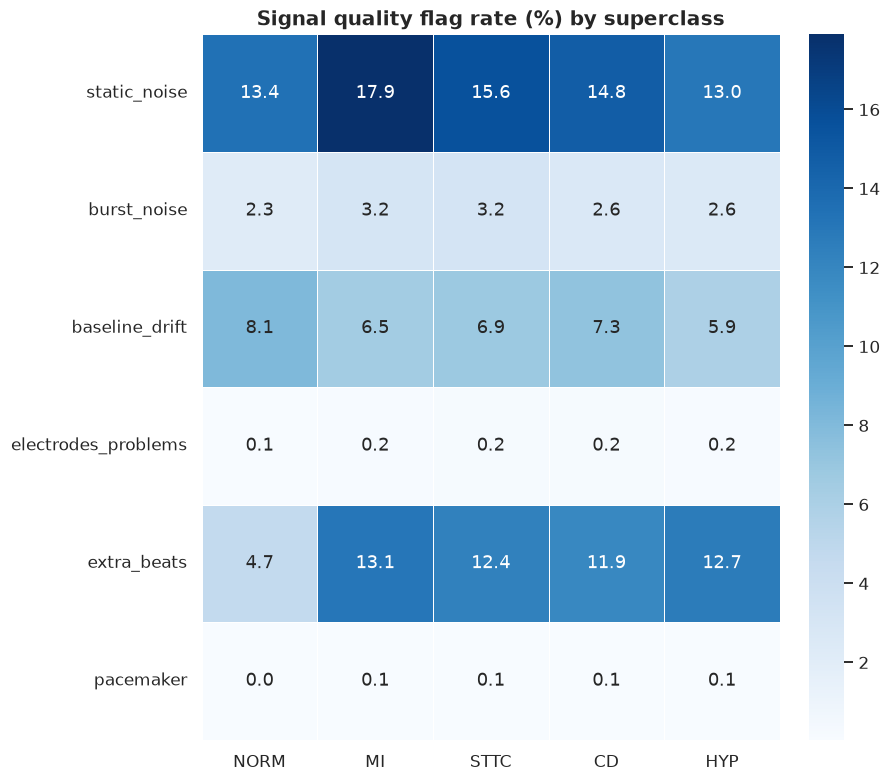

In [46]:
quality_rate_by_class = pd.DataFrame({superclass: quality_flags[superclass_matrix[superclass] == 1].mean() for superclass in SUPERCLASSES})
Charts.heatmap(quality_rate_by_class * 100, "Signal quality flag rate (%) by superclass", value_format=".1f")

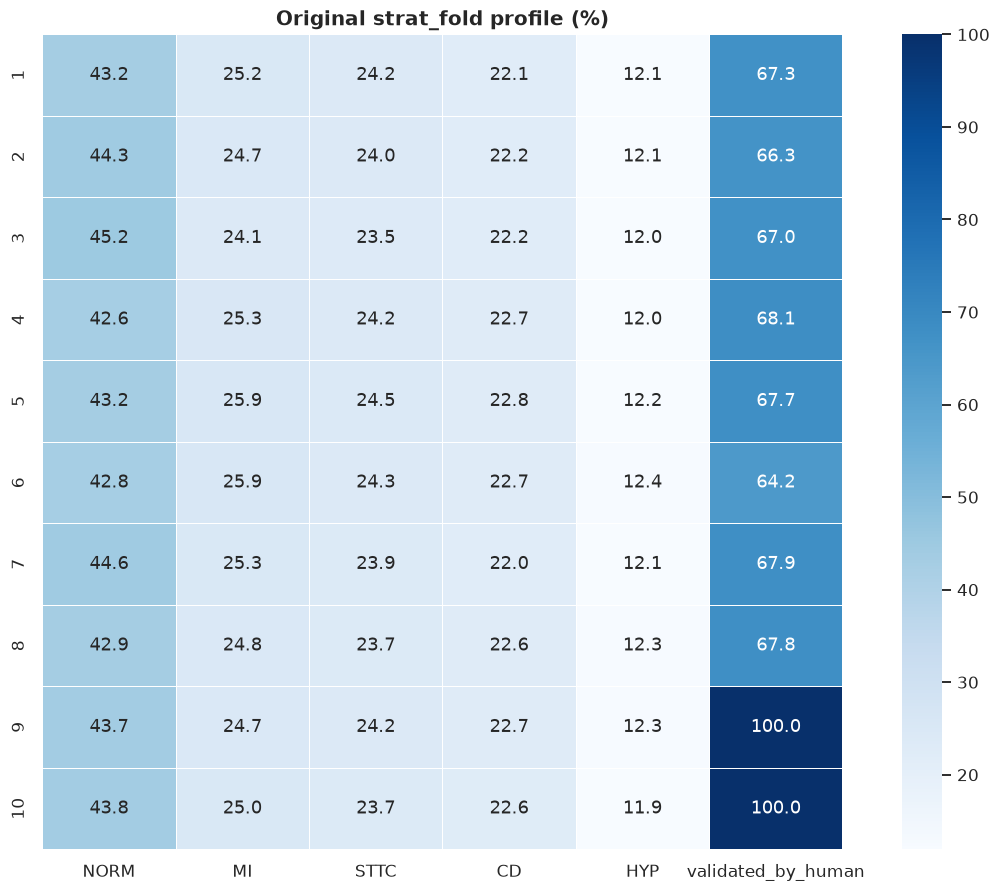

In [47]:
strat_fold_profile = superclass_matrix.assign(validated_by_human=database["validated_by_human"].astype(int)).groupby(database["strat_fold"]).mean()
Charts.heatmap(strat_fold_profile * 100, "Original strat_fold profile (%)", value_format=".1f", size=(9, 8))

In [48]:
database.groupby("strat_fold").agg(records=("patient_id", "size"), patients=("patient_id", "nunique"))

,records,patients
strat_fold,,
1,2175,1878
2,2181,1849
3,2192,1887
4,2174,1883
5,2174,1890
6,2173,1884
7,2176,1871
8,2173,1881
9,2183,1942


In [49]:
folds_per_patient = database.groupby("patient_id")["strat_fold"].nunique()
print(f"patients spread over more than one fold: {(folds_per_patient > 1).sum()}")

patients spread over more than one fold: 0


In [50]:
database.groupby("strat_fold").agg(mean_age=("age_capped", "mean"), female_ratio=("sex", "mean")).round(3)

,mean_age,female_ratio
strat_fold,,
1,59.680,0.478
2,59.504,0.479
3,59.672,0.482
4,60.054,0.477
5,59.700,0.477
6,59.702,0.477
7,59.852,0.477
8,59.703,0.479
9,60.458,0.481


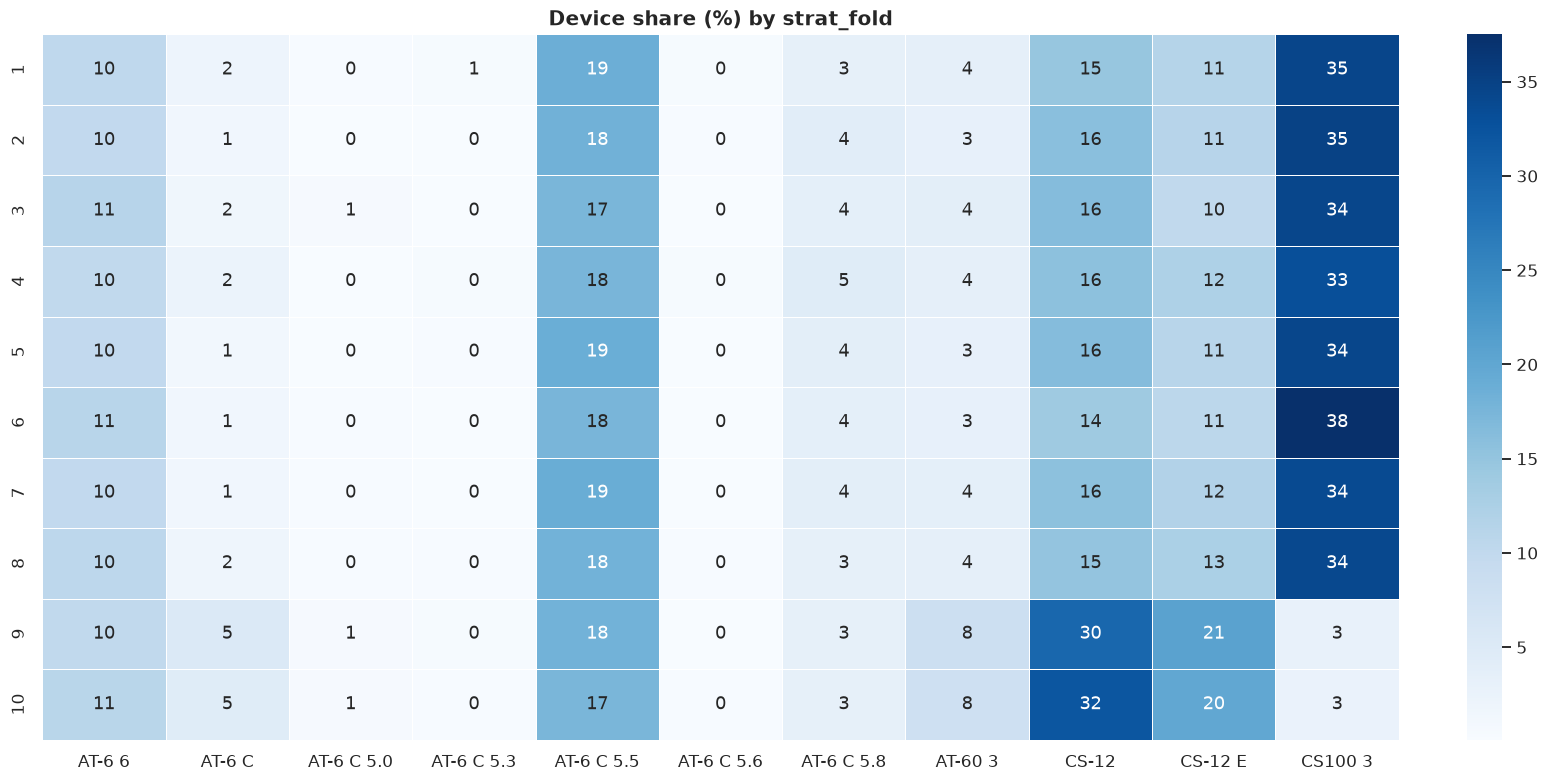

In [51]:
device_share_by_fold = pd.crosstab(database["strat_fold"], database["device"], normalize="index")
Charts.heatmap(device_share_by_fold * 100, "Device share (%) by strat_fold", value_format=".0f", size=FOLD_HEATMAP_SIZE)

In [52]:
under_adult_age = database["age_capped"].lt(MIN_ADULT_AGE)
pd.DataFrame({"no_superclass": without_superclass, "under_18": under_adult_age}).groupby(database["strat_fold"]).sum()

,no_superclass,under_18
strat_fold,,
1,36,10
2,43,14
3,42,13
4,44,12
5,39,12
6,44,23
7,42,16
8,44,11
9,37,9


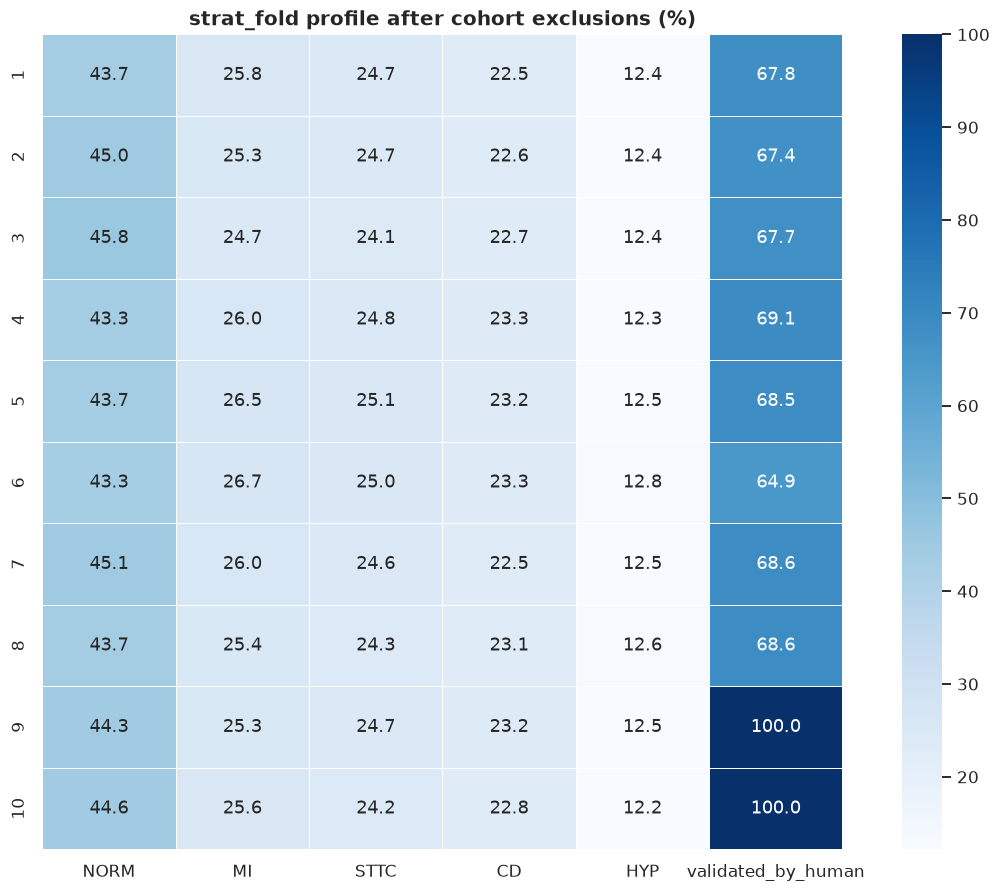

In [53]:
cohort_mask = ~without_superclass & ~under_adult_age
cohort = database[cohort_mask]
cohort_fold_profile = superclass_matrix[cohort_mask].assign(validated_by_human=cohort["validated_by_human"].astype(int)).groupby(cohort["strat_fold"]).mean()
Charts.heatmap(cohort_fold_profile * 100, "strat_fold profile after cohort exclusions (%)", value_format=".1f", size=(9, 8))

In [54]:
rng = np.random.default_rng(RANDOM_SEED)
selector = RecordSelector(database, rng)
example_id = selector.clean_record()

In [55]:
for rate in RATE_FILENAME_COLUMNS:
    header = signals.header(example_id, rate)
    print(f"{rate} Hz | fs={header.fs} | length={header.sig_len} | leads={header.n_sig} | units={set(header.units)} | names match: {tuple(header.sig_name) == LEAD_NAMES}")

100 Hz | fs=100 | length=1000 | leads=12 | units={'mV'} | names match: True
500 Hz | fs=500 | length=5000 | leads=12 | units={'mV'} | names match: True


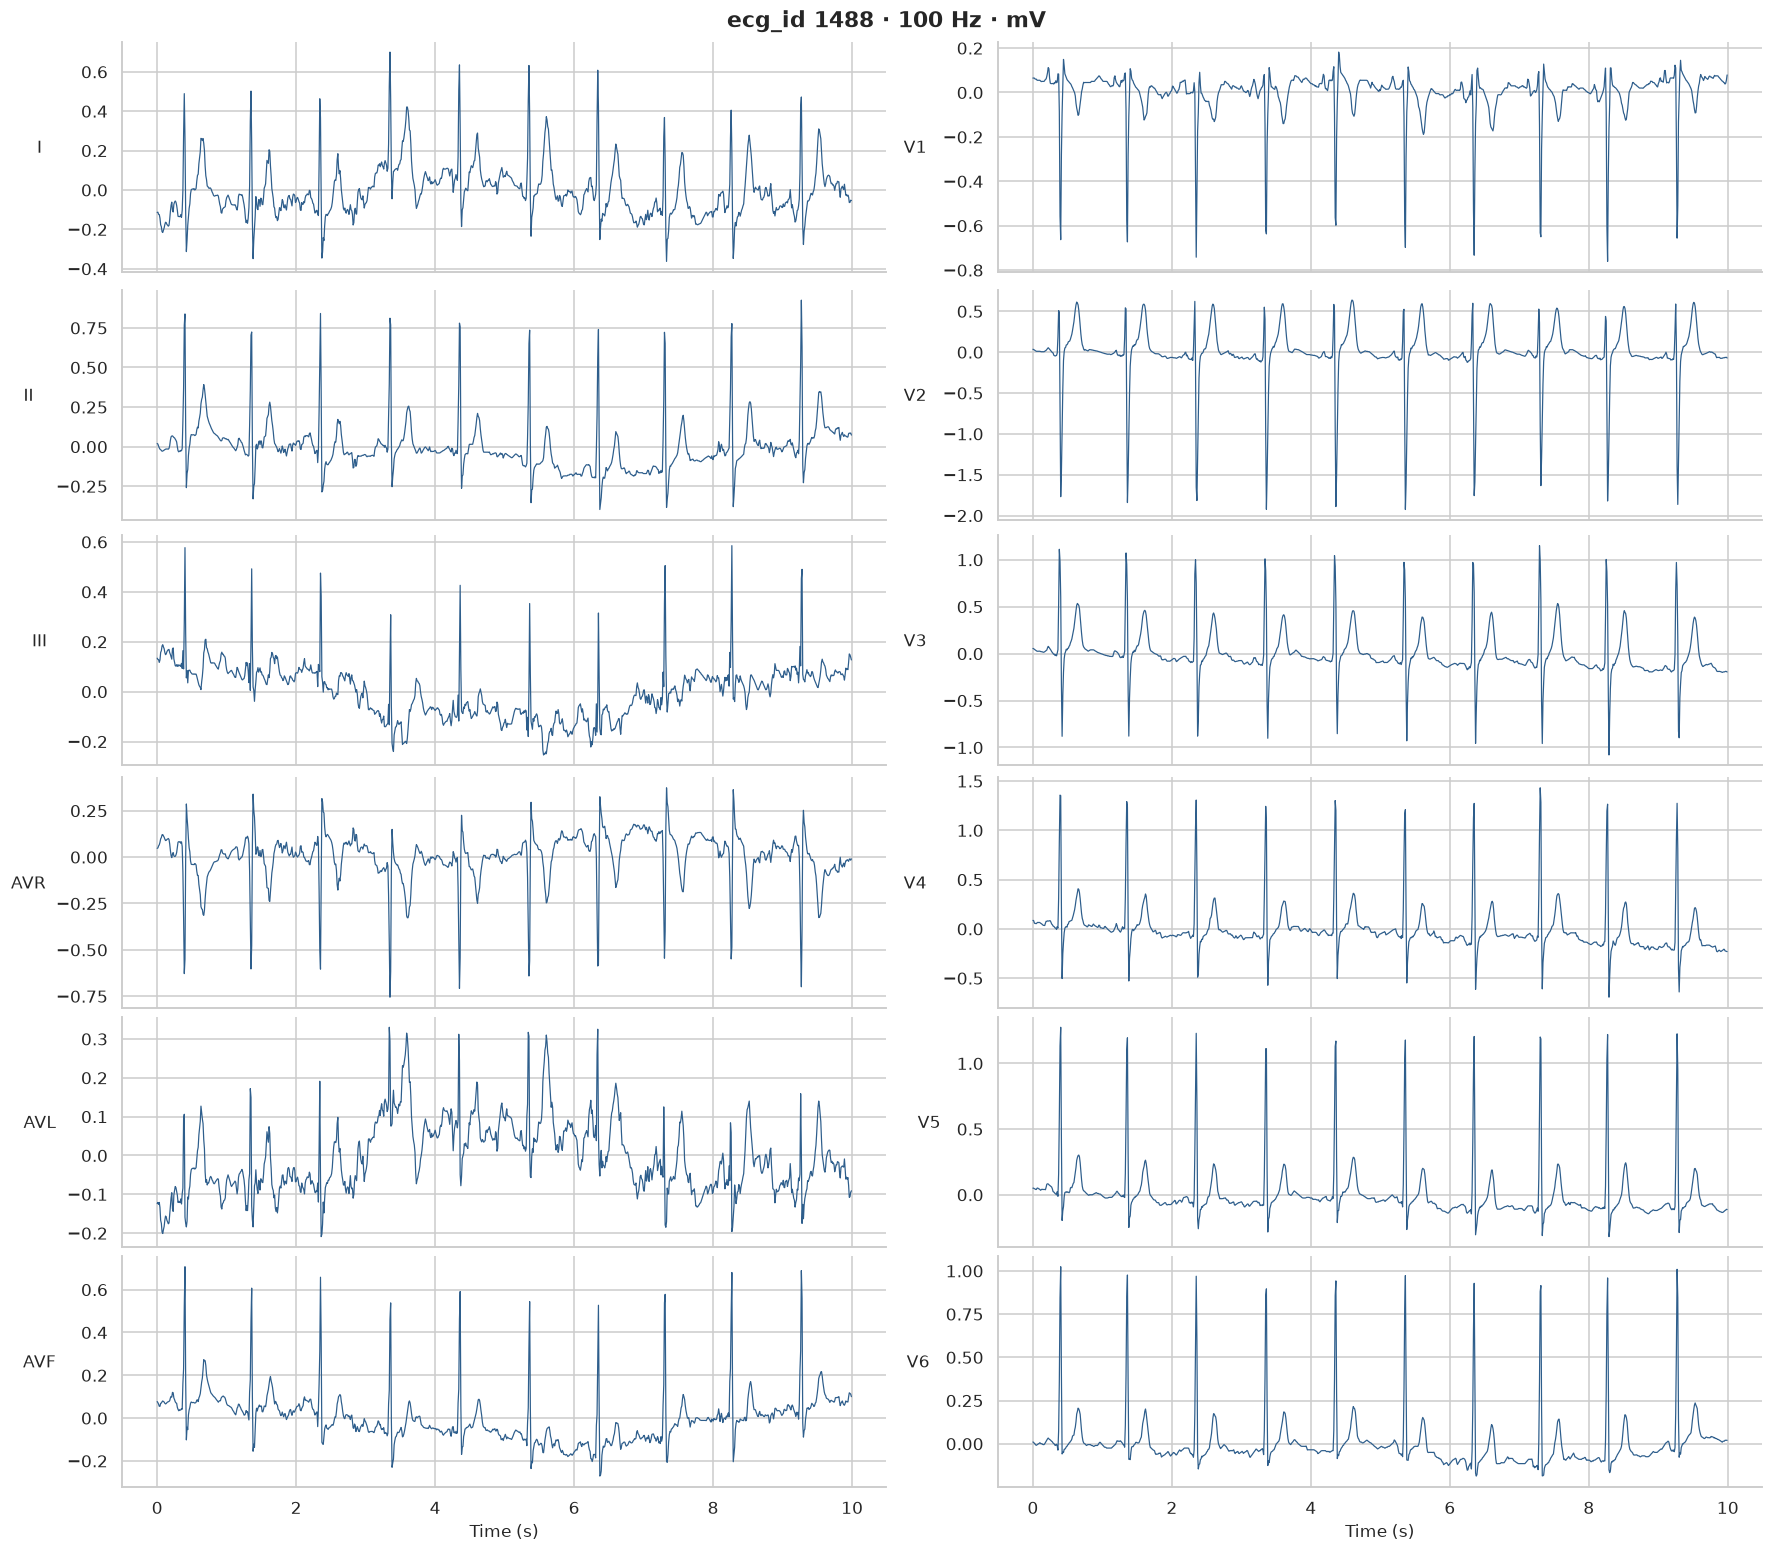

In [56]:
Charts.leads(signals.load(example_id, LOW_RATE), LOW_RATE, f"ecg_id {example_id} · {LOW_RATE} Hz · mV")

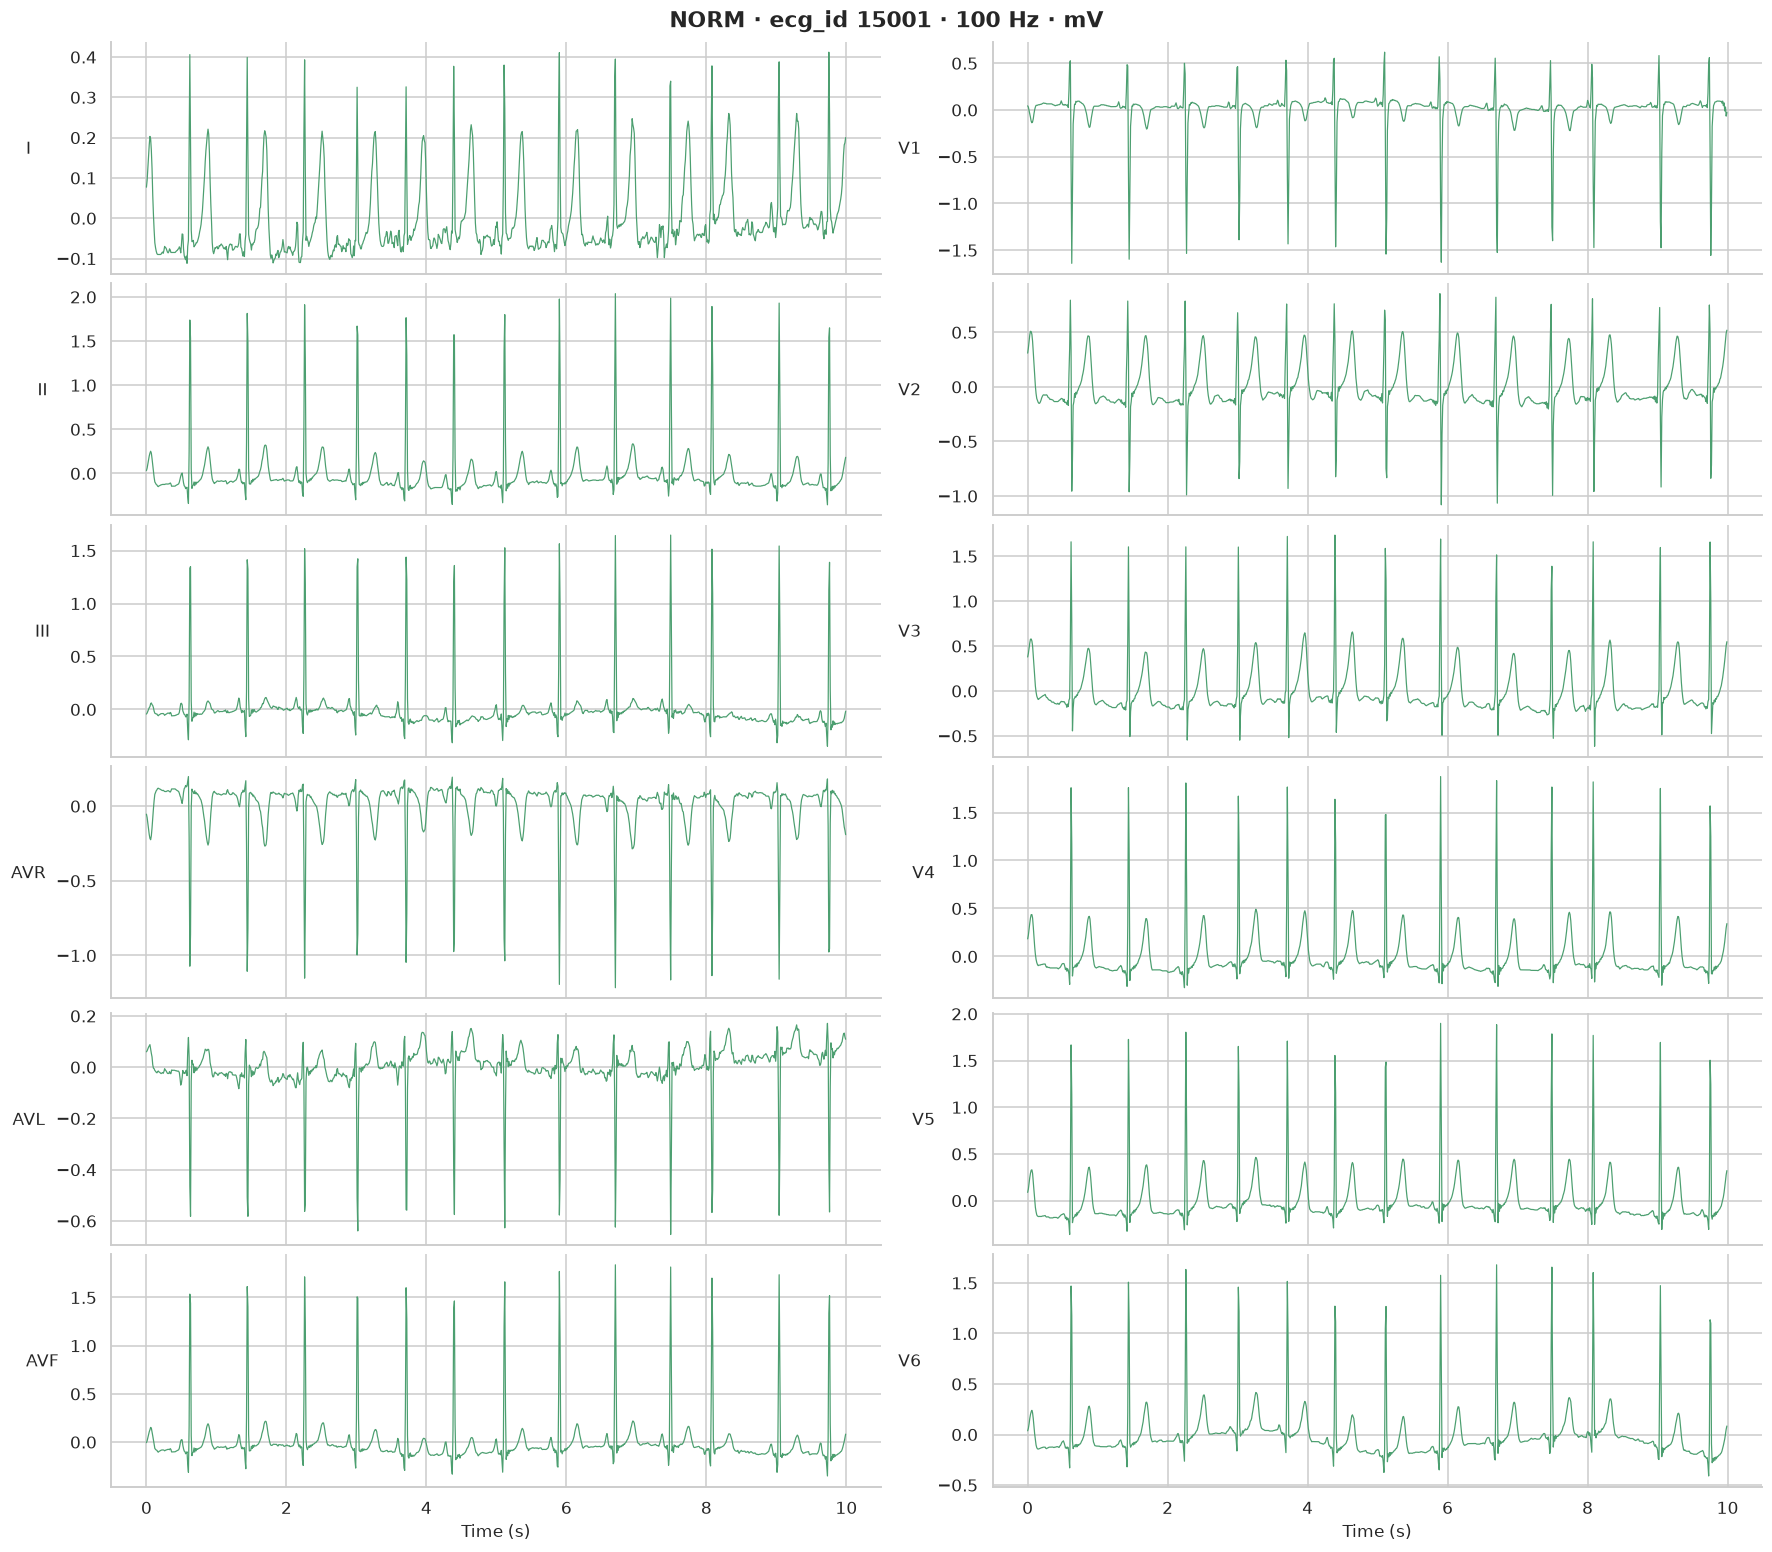

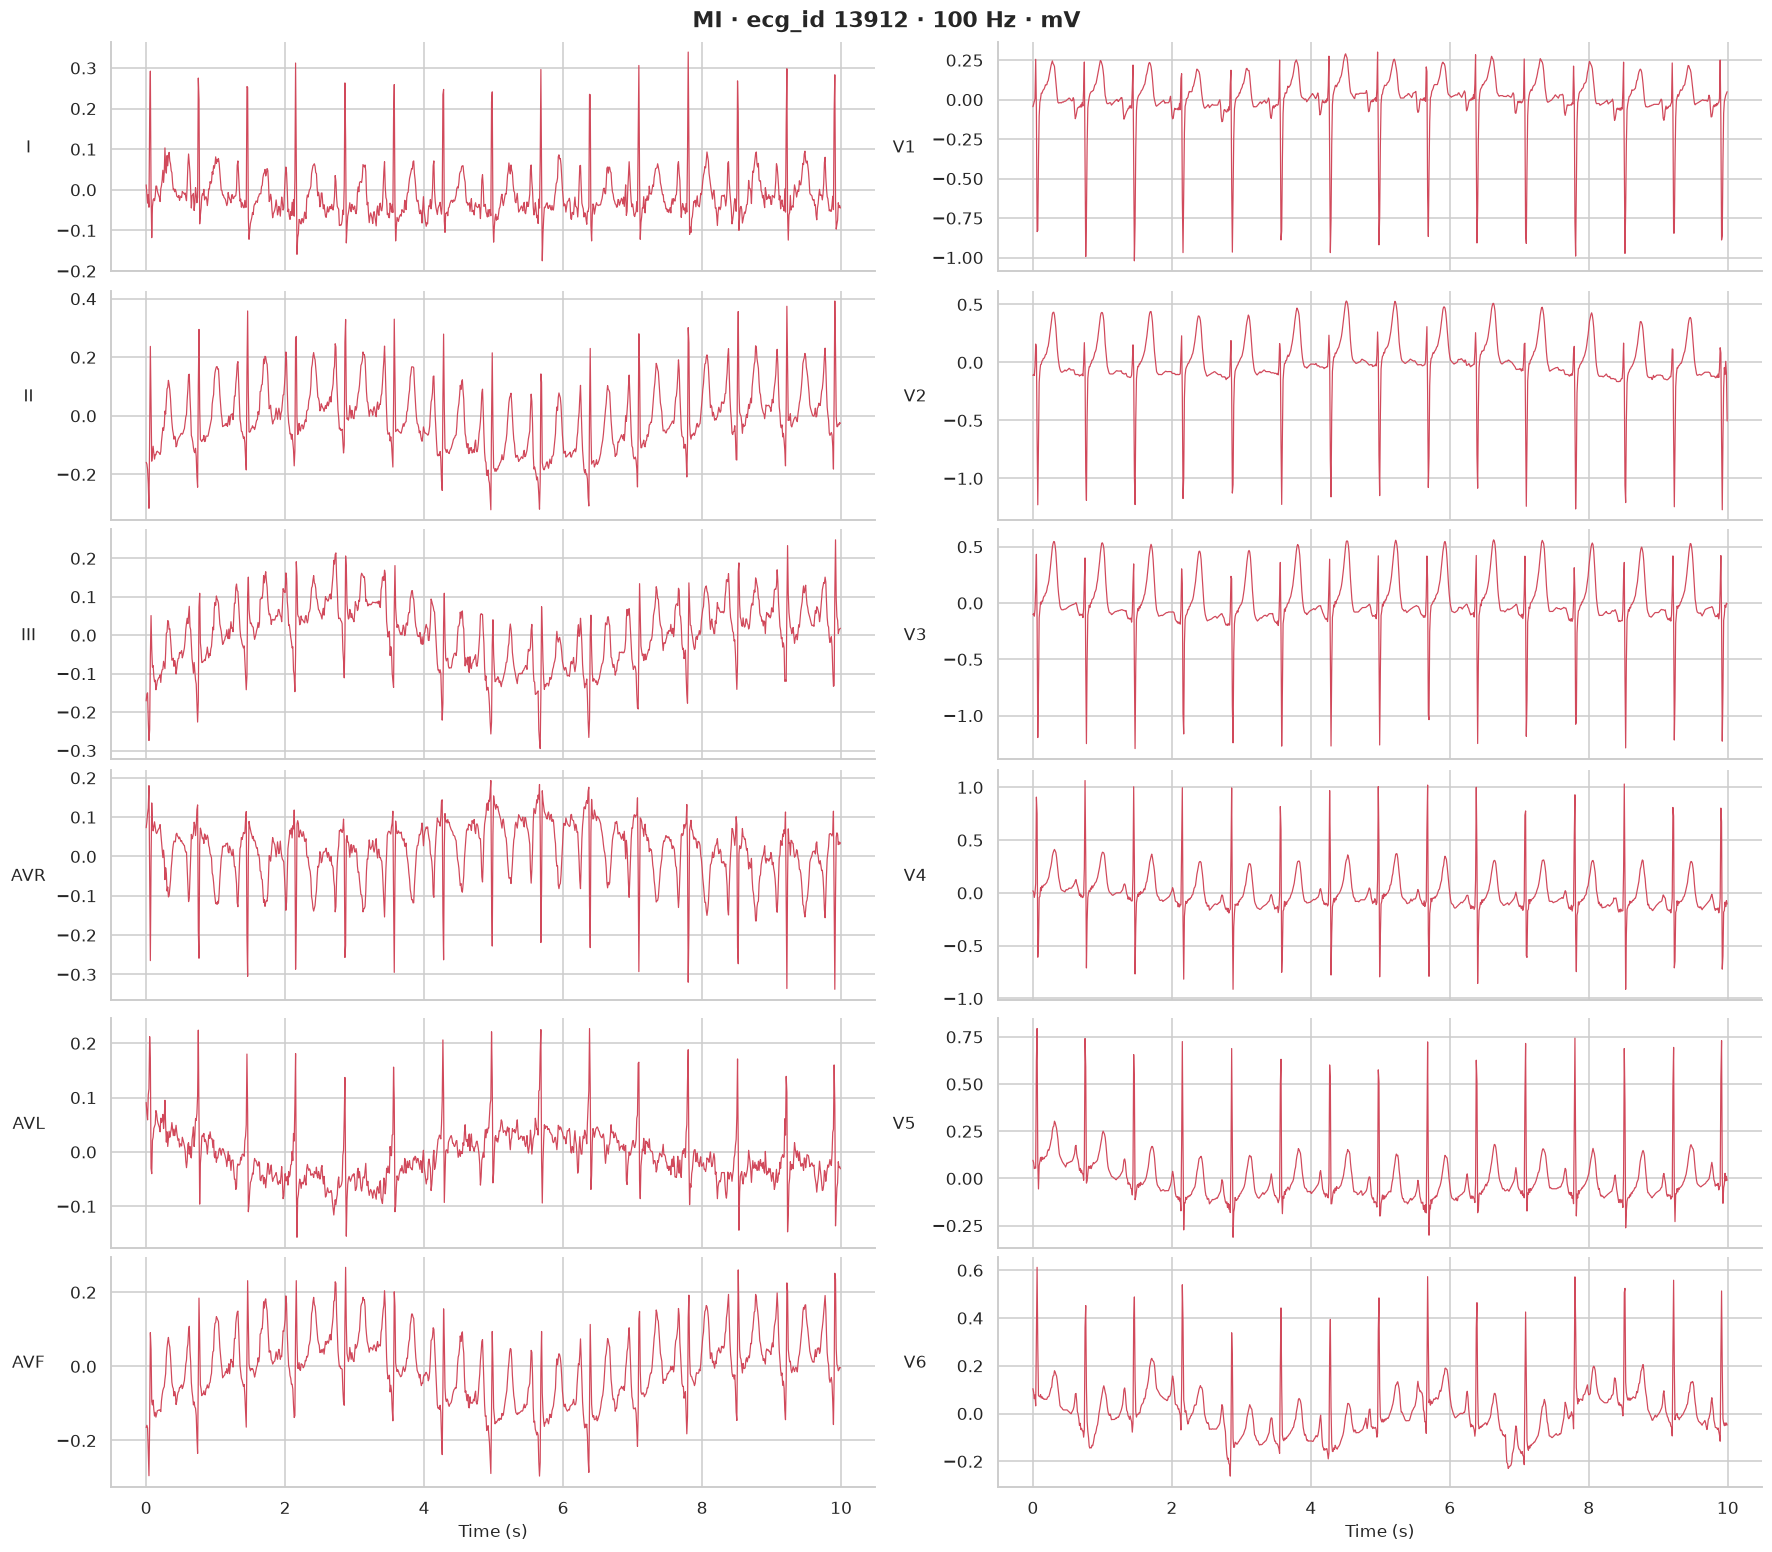

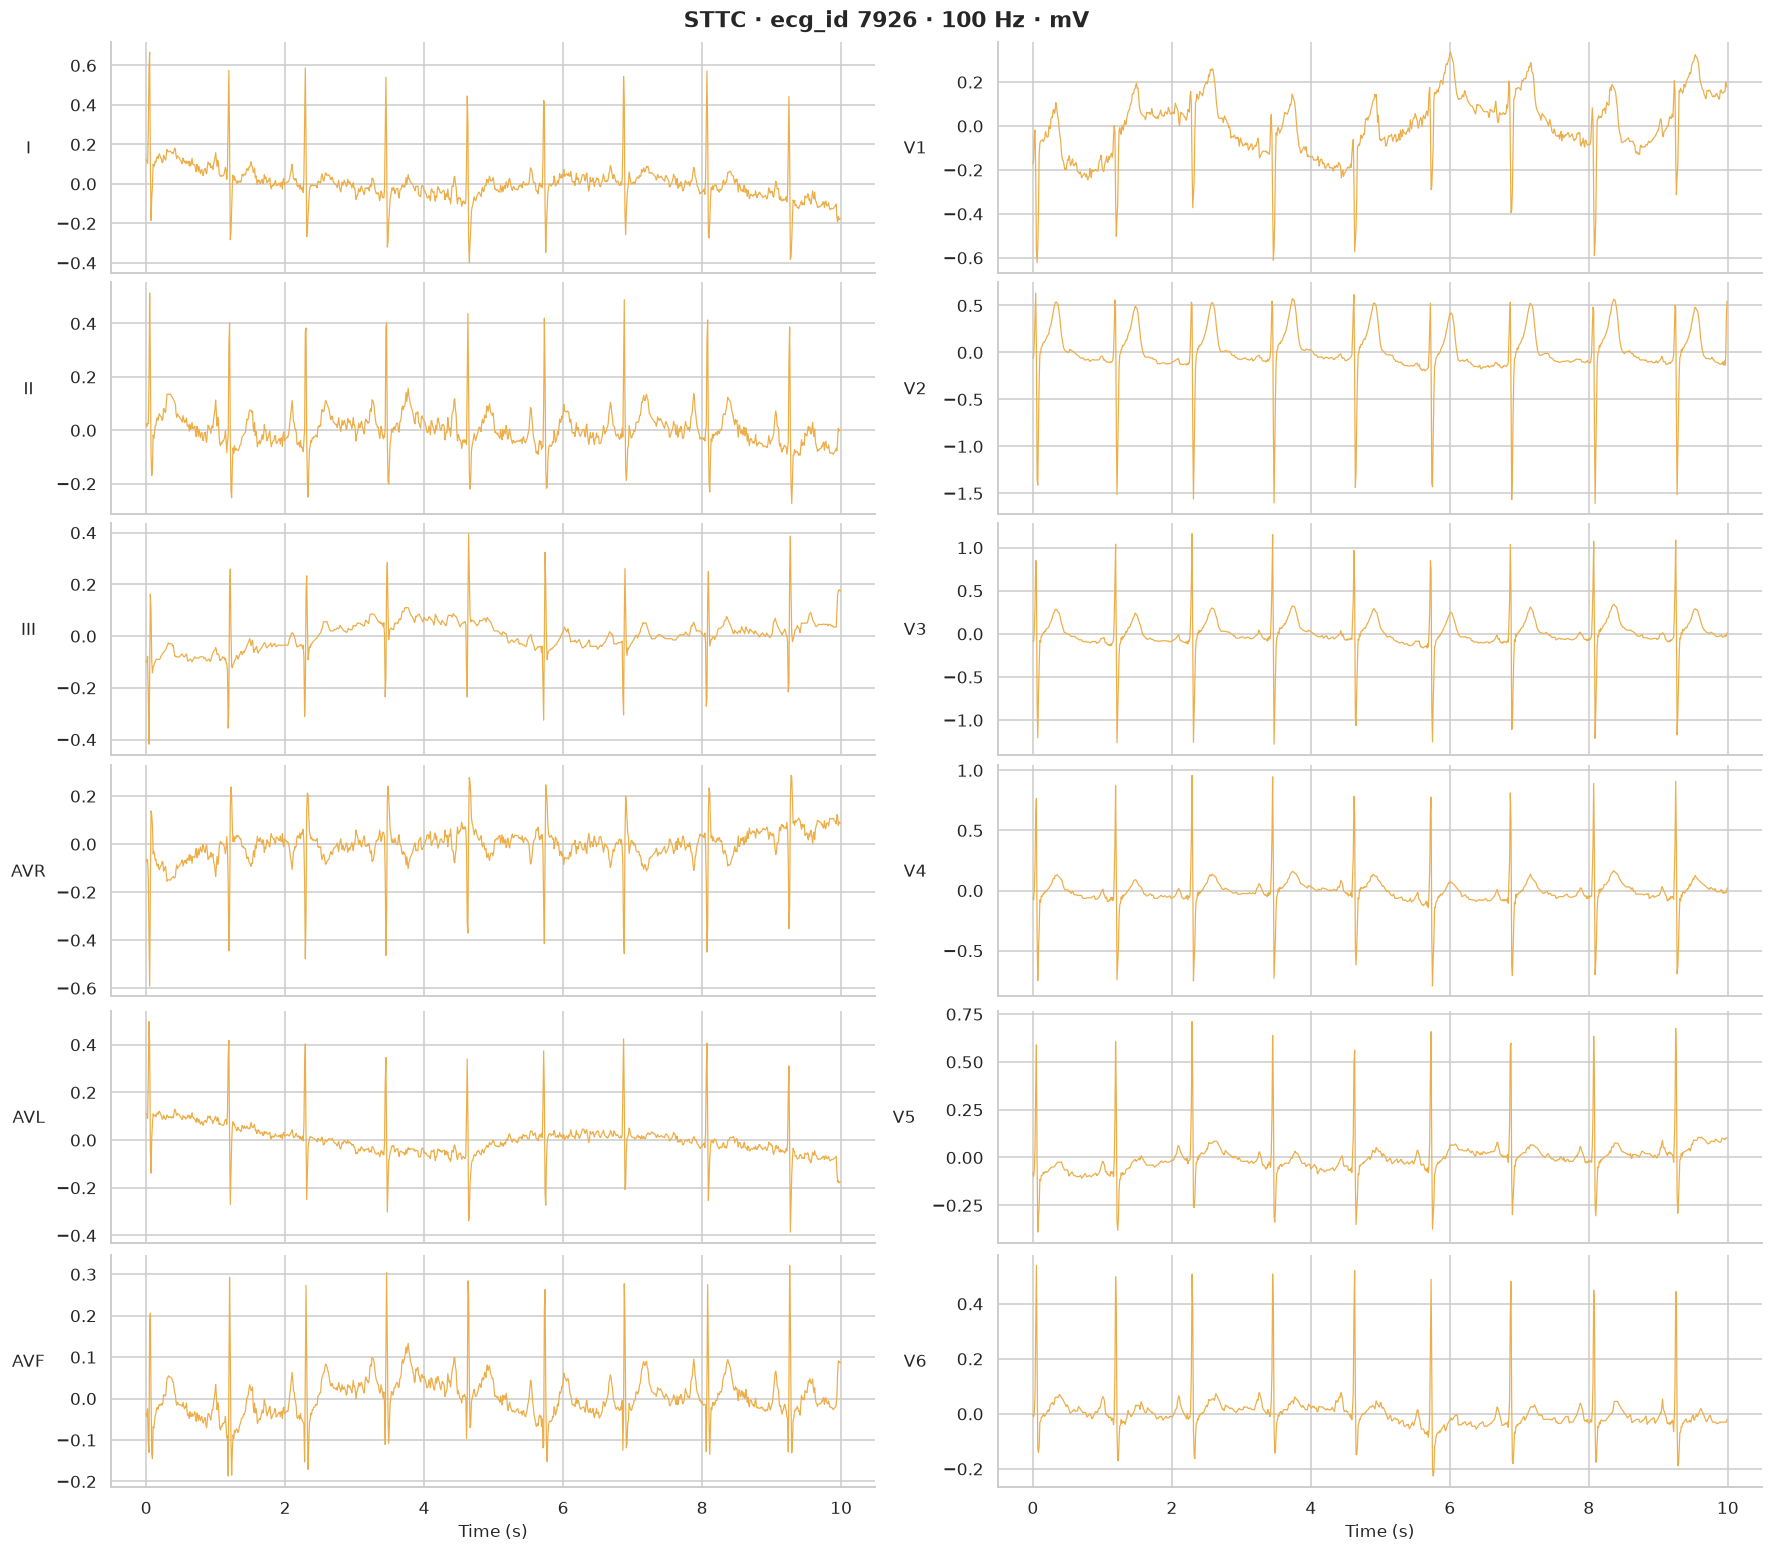

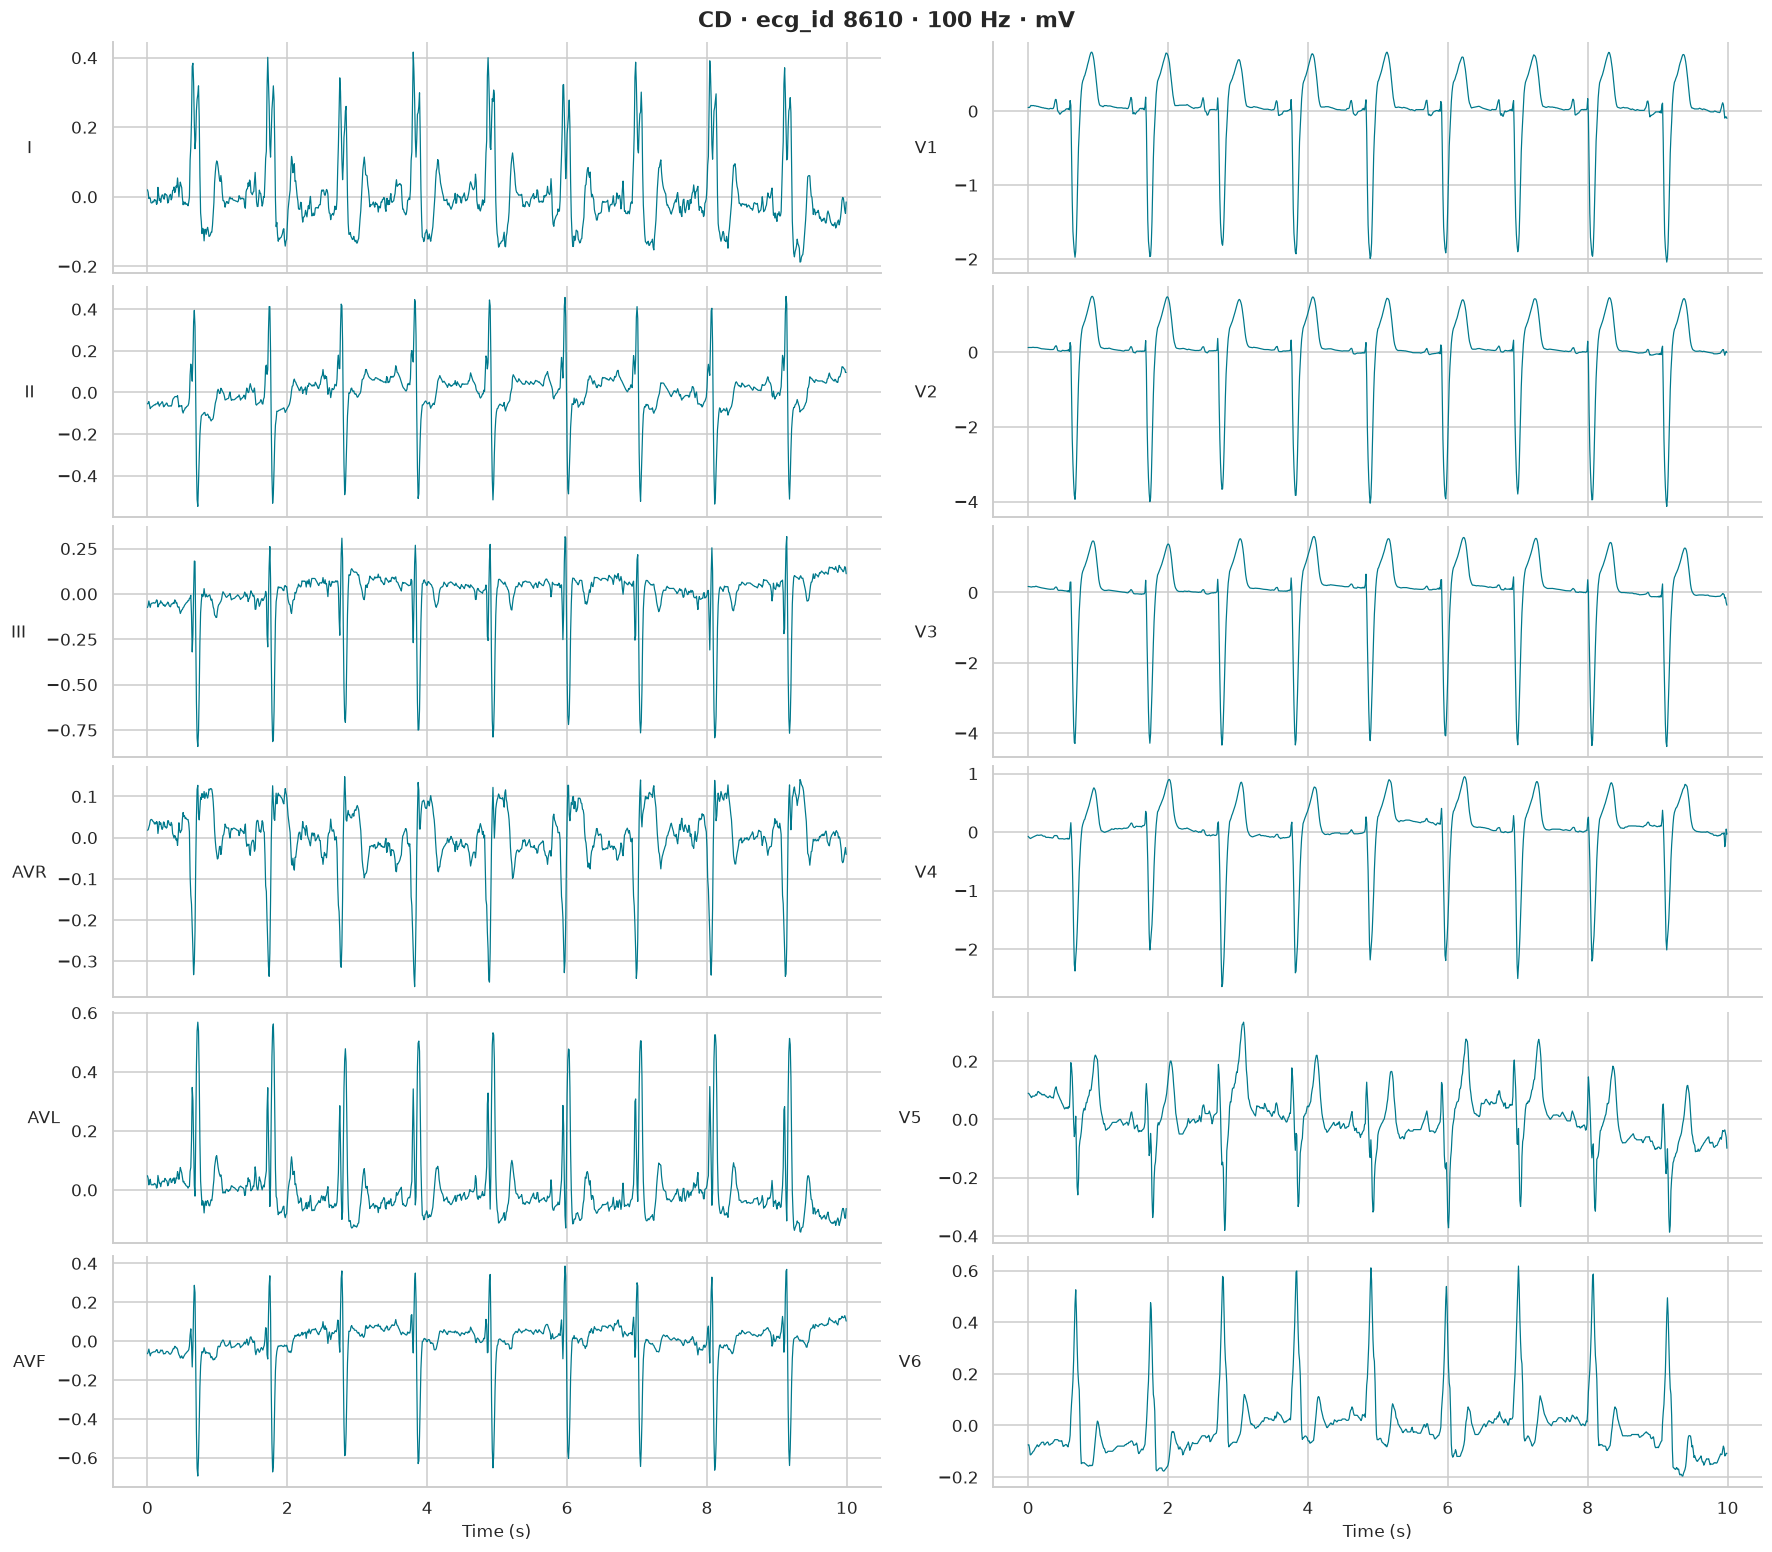

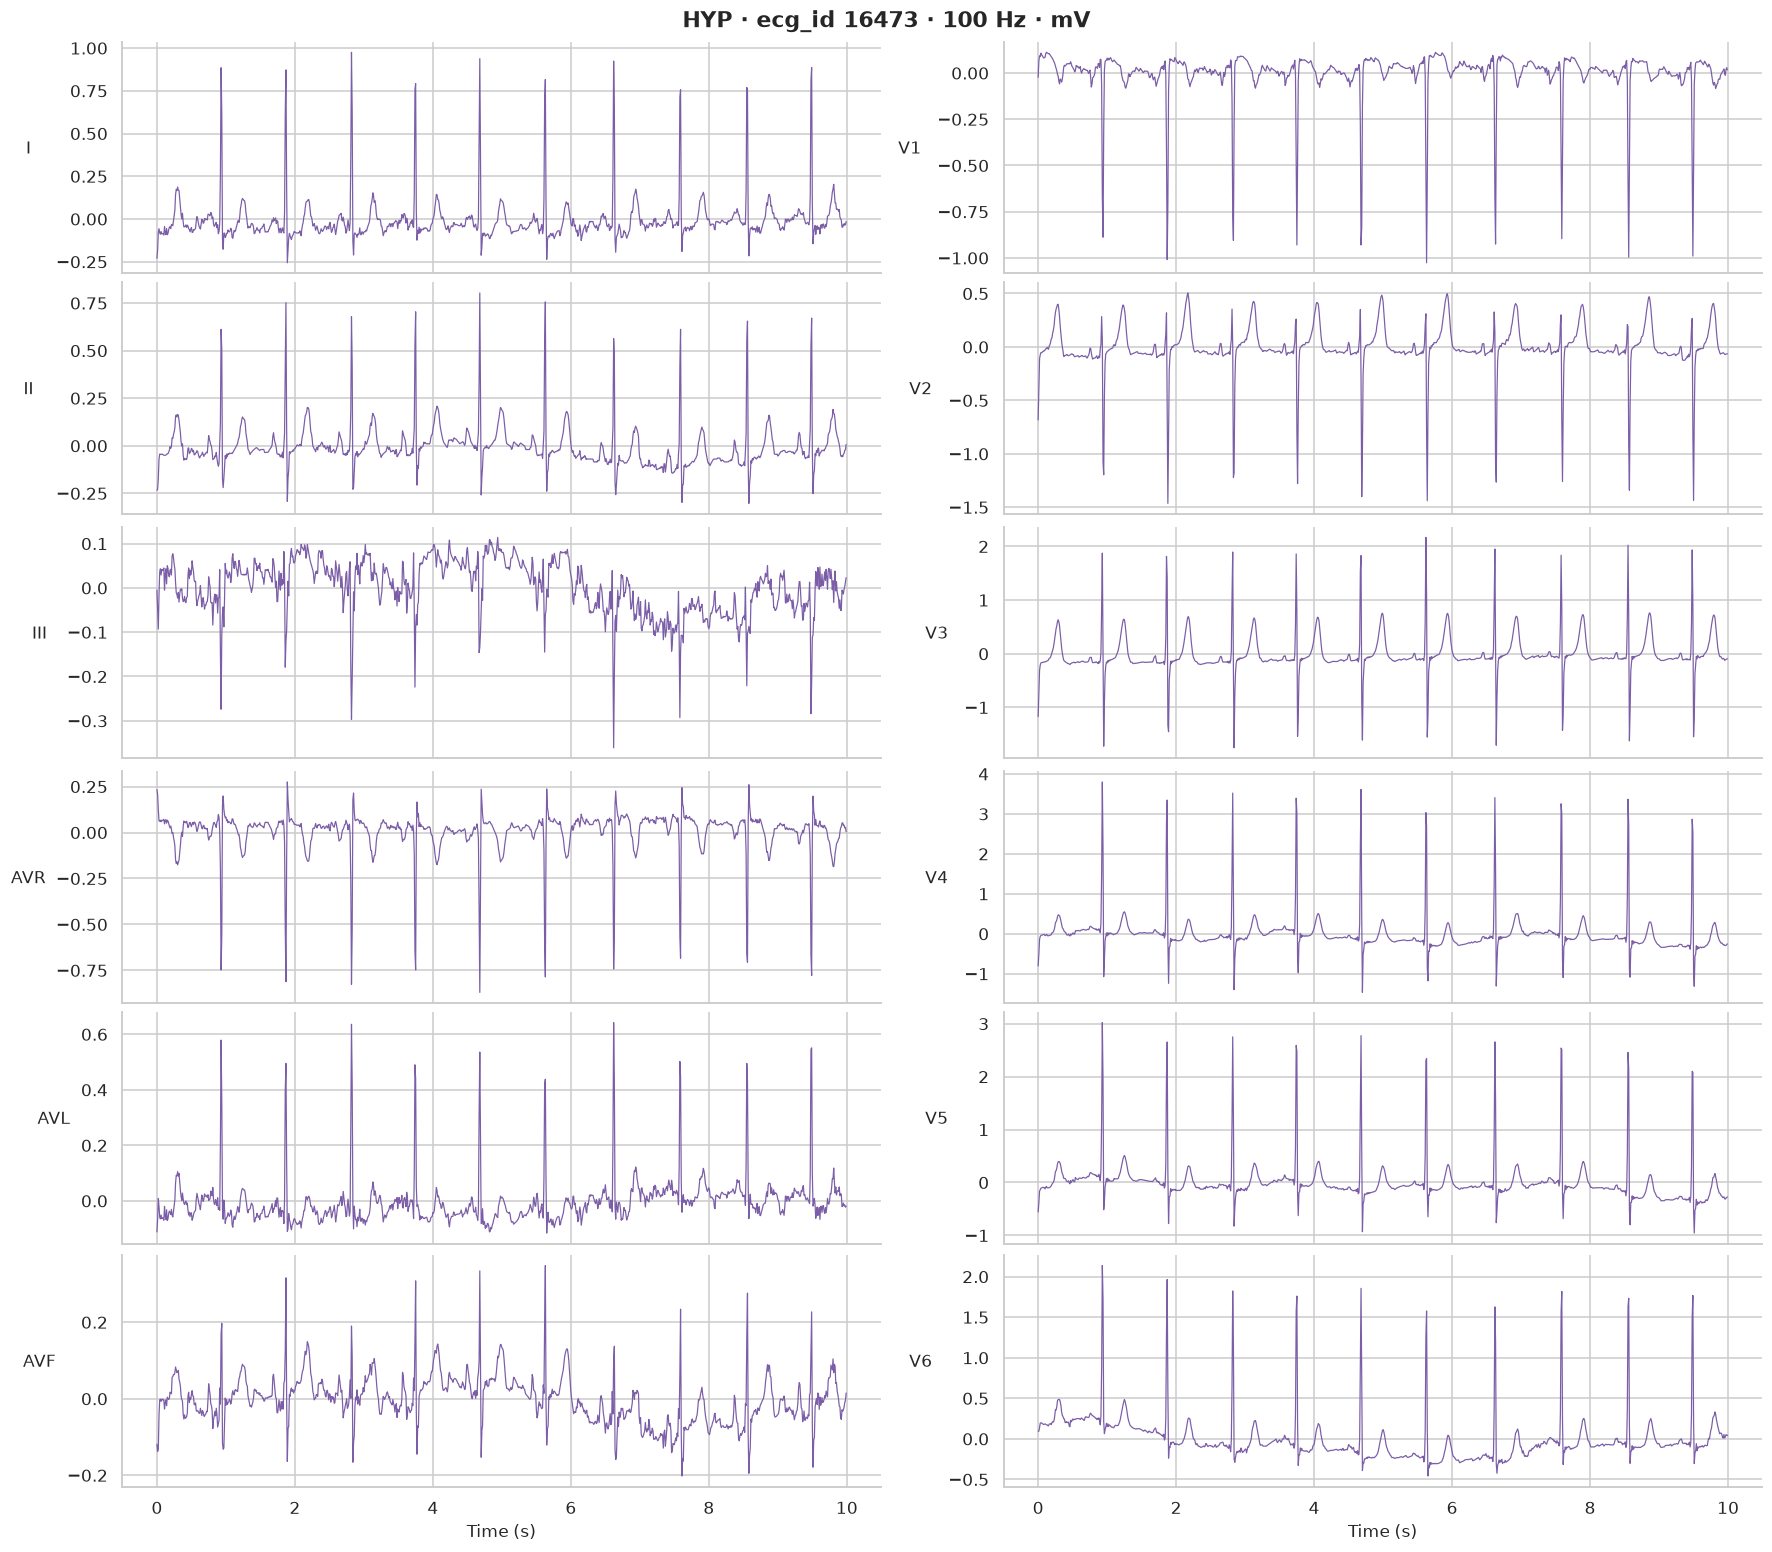

In [57]:
for superclass in SUPERCLASSES:
    ecg_id = selector.single_superclass(superclass)
    Charts.leads(signals.load(ecg_id, LOW_RATE), LOW_RATE, f"{superclass} · ecg_id {ecg_id} · {LOW_RATE} Hz · mV", color=SUPERCLASS_COLORS[superclass])

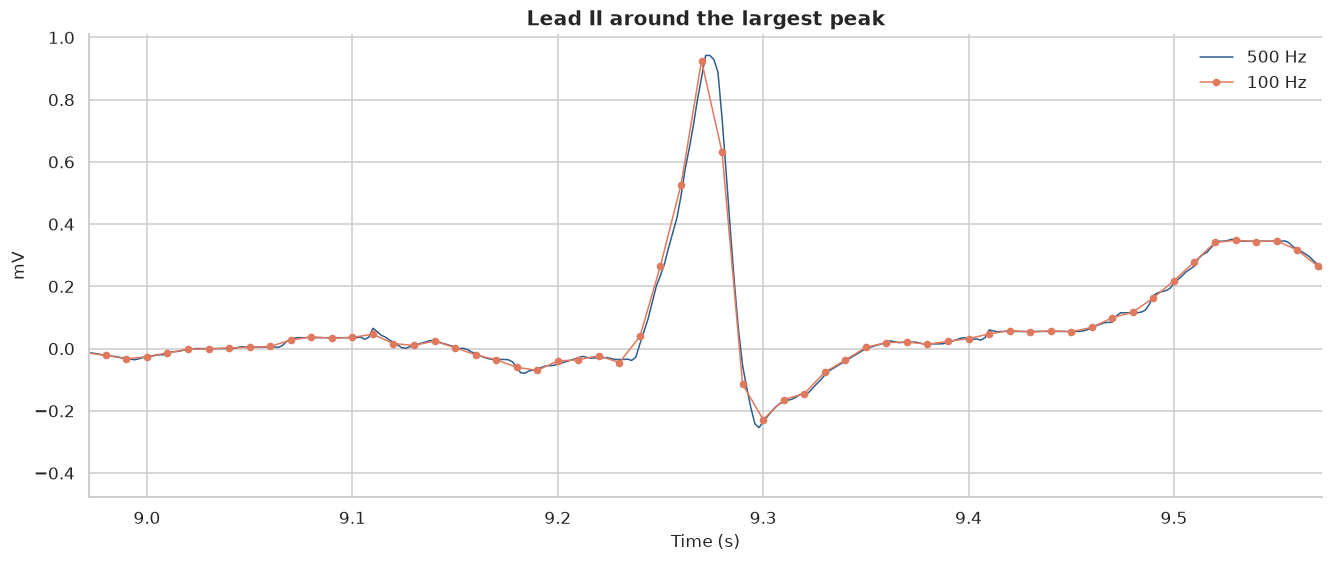

In [58]:
lead_index = LEAD_NAMES.index(REFERENCE_LEAD)
low_signal = signals.load(example_id, LOW_RATE)
high_signal = signals.load(example_id, HIGH_RATE)
peak_time = SignalInspector.peak_time(high_signal, HIGH_RATE, lead_index)
traces = [
    Trace(f"{HIGH_RATE} Hz", SignalInspector.time_axis(high_signal, HIGH_RATE), high_signal[:, lead_index], PRIMARY_COLOR),
    Trace(f"{LOW_RATE} Hz", SignalInspector.time_axis(low_signal, LOW_RATE), low_signal[:, lead_index], SECONDARY_COLOR, "o")
]
zoom_window = (peak_time - ZOOM_HALF_WIDTH_SECONDS, peak_time + ZOOM_HALF_WIDTH_SECONDS)
Charts.overlay(traces, f"Lead {REFERENCE_LEAD} around the largest peak", "Time (s)", "mV", xlim=zoom_window)

In [59]:
spectrum_ids = rng.choice(database.index, SPECTRUM_SAMPLE_SIZE, replace=False)
frequencies, power = SignalInspector.power_spectrum(signals.load_many(spectrum_ids, HIGH_RATE), HIGH_RATE)
mean_power = pd.DataFrame(power.mean(axis=0), index=frequencies, columns=LEAD_NAMES)

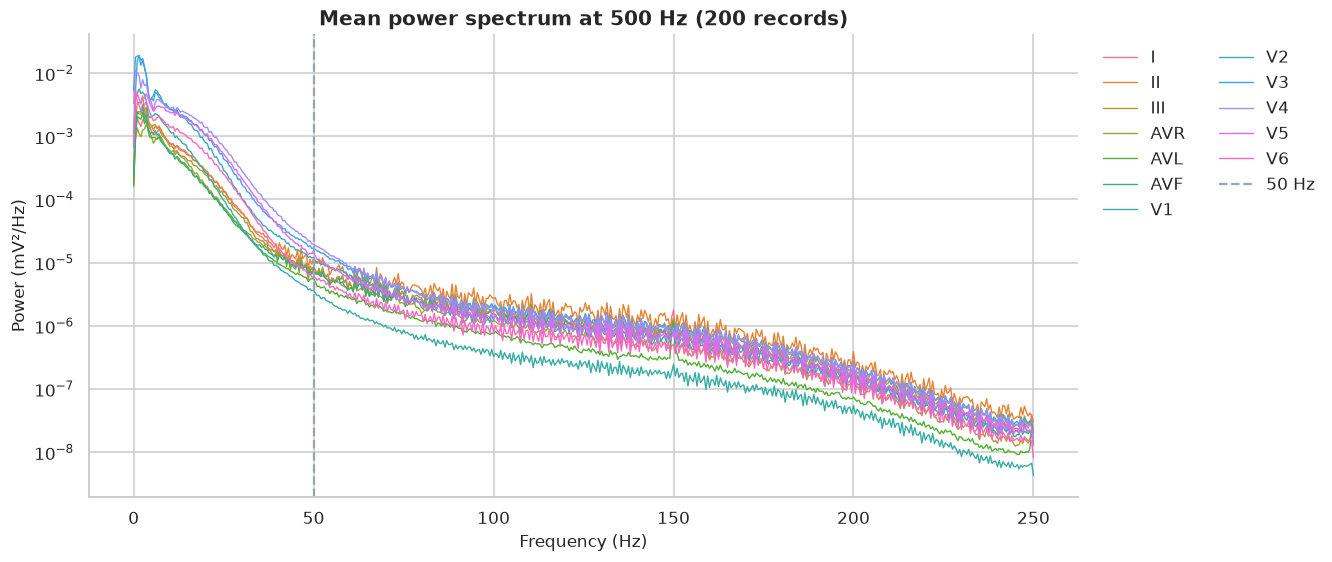

In [60]:
Charts.spectrum(mean_power, f"Mean power spectrum at {HIGH_RATE} Hz ({SPECTRUM_SAMPLE_SIZE} records)", LOW_RATE / 2)

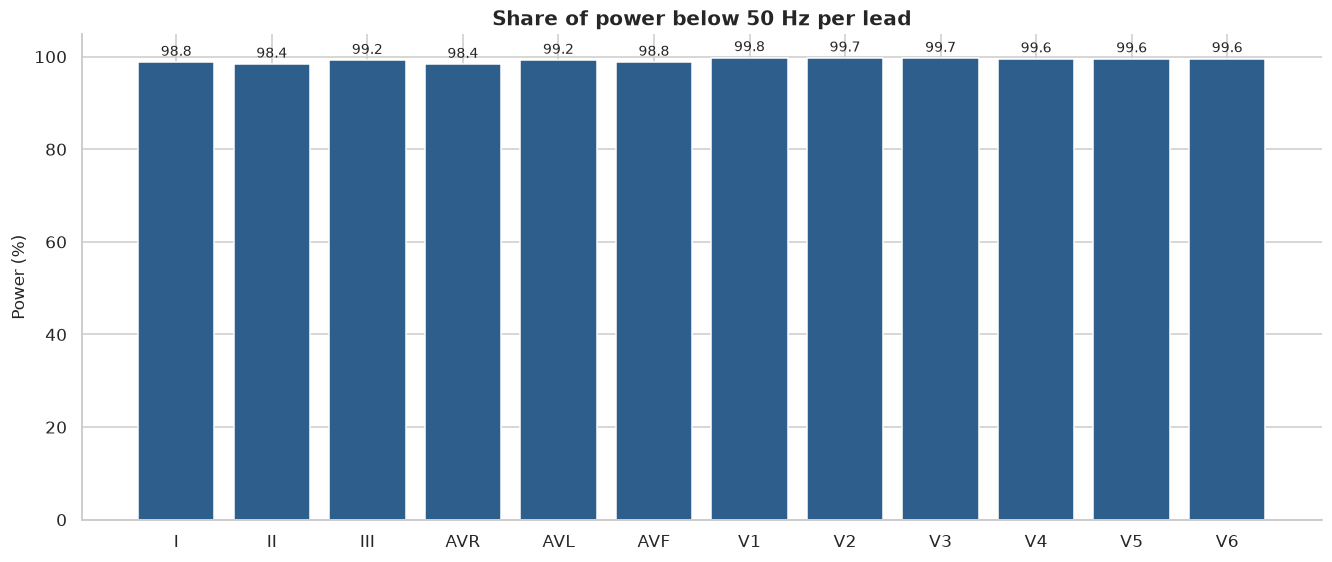

In [61]:
cumulative_energy = mean_power.cumsum() / mean_power.sum()
energy_below_low_nyquist = cumulative_energy[cumulative_energy.index <= LOW_RATE / 2].iloc[-1]
Charts.bar(energy_below_low_nyquist * 100, f"Share of power below {LOW_RATE / 2:g} Hz per lead", ylabel="Power (%)", value_format="%.1f")

In [62]:
amplitude_ids = rng.choice(database.index, SIGNAL_SAMPLE_SIZE, replace=False)
low_rate_batch = signals.load_many(amplitude_ids, LOW_RATE)

In [63]:
pd.DataFrame({
    "mean": low_rate_batch.mean(axis=(0, 1)),
    "std": low_rate_batch.std(axis=(0, 1)),
    "p01": np.percentile(low_rate_batch, 1, axis=(0, 1)),
    "p99": np.percentile(low_rate_batch, 99, axis=(0, 1)),
    "min": low_rate_batch.min(axis=(0, 1)),
    "max": low_rate_batch.max(axis=(0, 1))
}, index=LEAD_NAMES).round(3)

,mean,std,p01,p99,min,max
I,-0.002,0.150,-0.275,0.694,-1.797,1.711
II,-0.001,0.166,-0.364,0.662,-1.854,3.512
III,0.001,0.165,-0.582,0.442,-3.121,3.461
AVR,0.002,0.135,-0.623,0.252,-2.432,1.139
AVL,-0.002,0.134,-0.285,0.571,-2.534,2.301
AVF,0.000,0.147,-0.395,0.474,-2.399,2.835
V1,-0.000,0.236,-0.969,0.512,-5.635,3.298
V2,-0.001,0.356,-1.387,0.842,-8.612,6.457
V3,-0.002,0.360,-1.258,0.994,-6.904,7.406
V4,-0.001,0.317,-0.869,1.217,-5.695,5.454


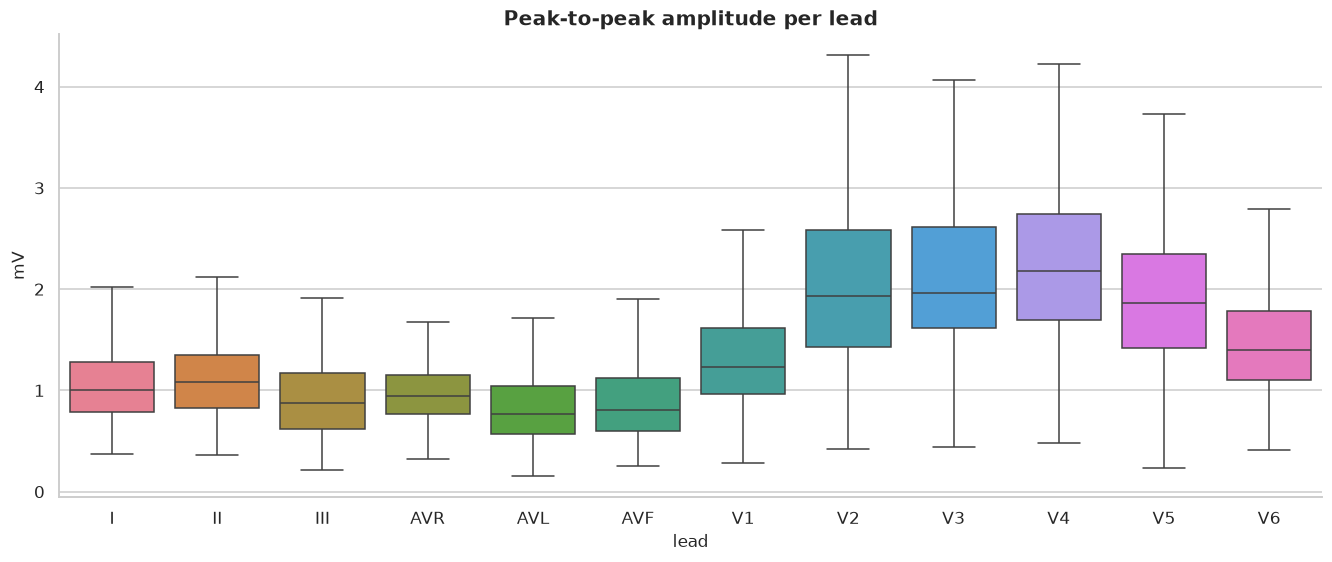

In [64]:
peak_to_peak = pd.DataFrame(np.ptp(low_rate_batch, axis=1), columns=LEAD_NAMES).melt(var_name="lead", value_name="peak_to_peak")
Charts.box_by_group(peak_to_peak, "peak_to_peak", "lead", "Peak-to-peak amplitude per lead", "mV", order=list(LEAD_NAMES))

In [65]:
integrity = pd.DataFrame.from_dict({ecg_id: SignalInspector.integrity_report(signals.load(ecg_id, LOW_RATE)) for ecg_id in database.index}, orient="index")

lengths: {1000: 21799}


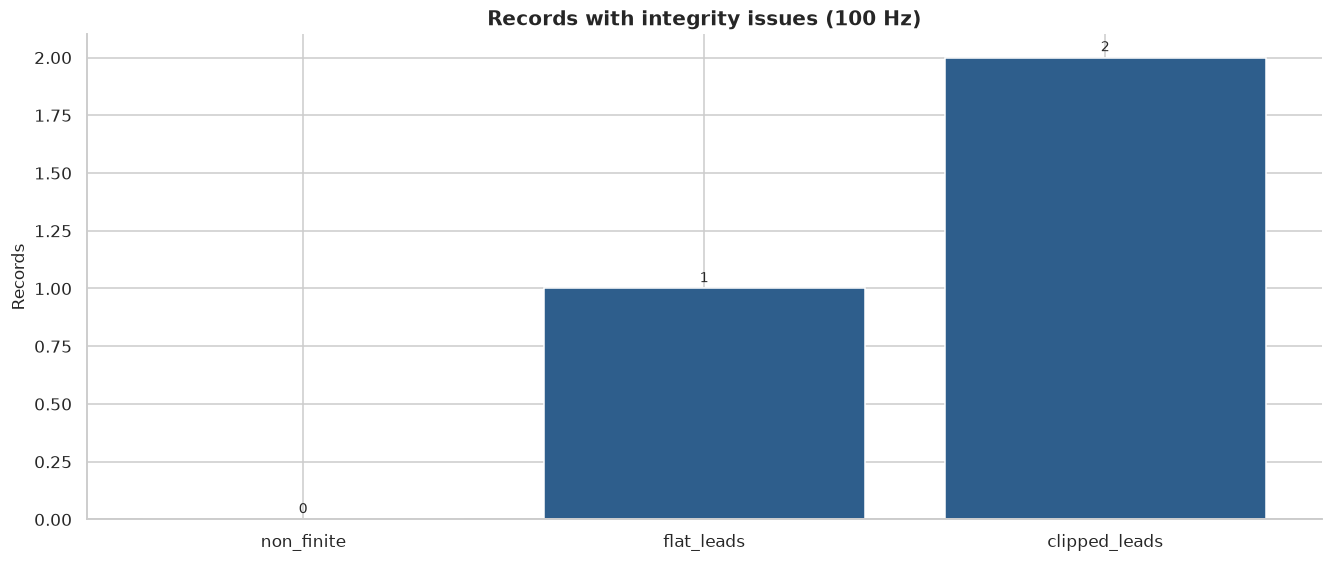

In [66]:
print(f"lengths: {integrity['length'].value_counts().to_dict()}")
issue_counts = (integrity[["non_finite", "flat_leads", "clipped_leads"]] > 0).sum()
Charts.bar(issue_counts, f"Records with integrity issues ({LOW_RATE} Hz)", ylabel="Records")

In [67]:
duplicate_signals = integrity["fingerprint"].duplicated(keep=False)
print(f"records sharing an identical 100 Hz signal: {duplicate_signals.sum()}")
database.loc[duplicate_signals[duplicate_signals].index, ["patient_id", "recording_date", "superclasses"]].join(integrity["fingerprint"]).sort_values("fingerprint")

records sharing an identical 100 Hz signal: 0


,patient_id,recording_date,superclasses,fingerprint


In [ ]:
high_rate_lengths = pd.Series({ecg_id: signals.header(ecg_id, HIGH_RATE).sig_len for ecg_id in database.index})
high_rate_lengths.value_counts().to_frame("records")

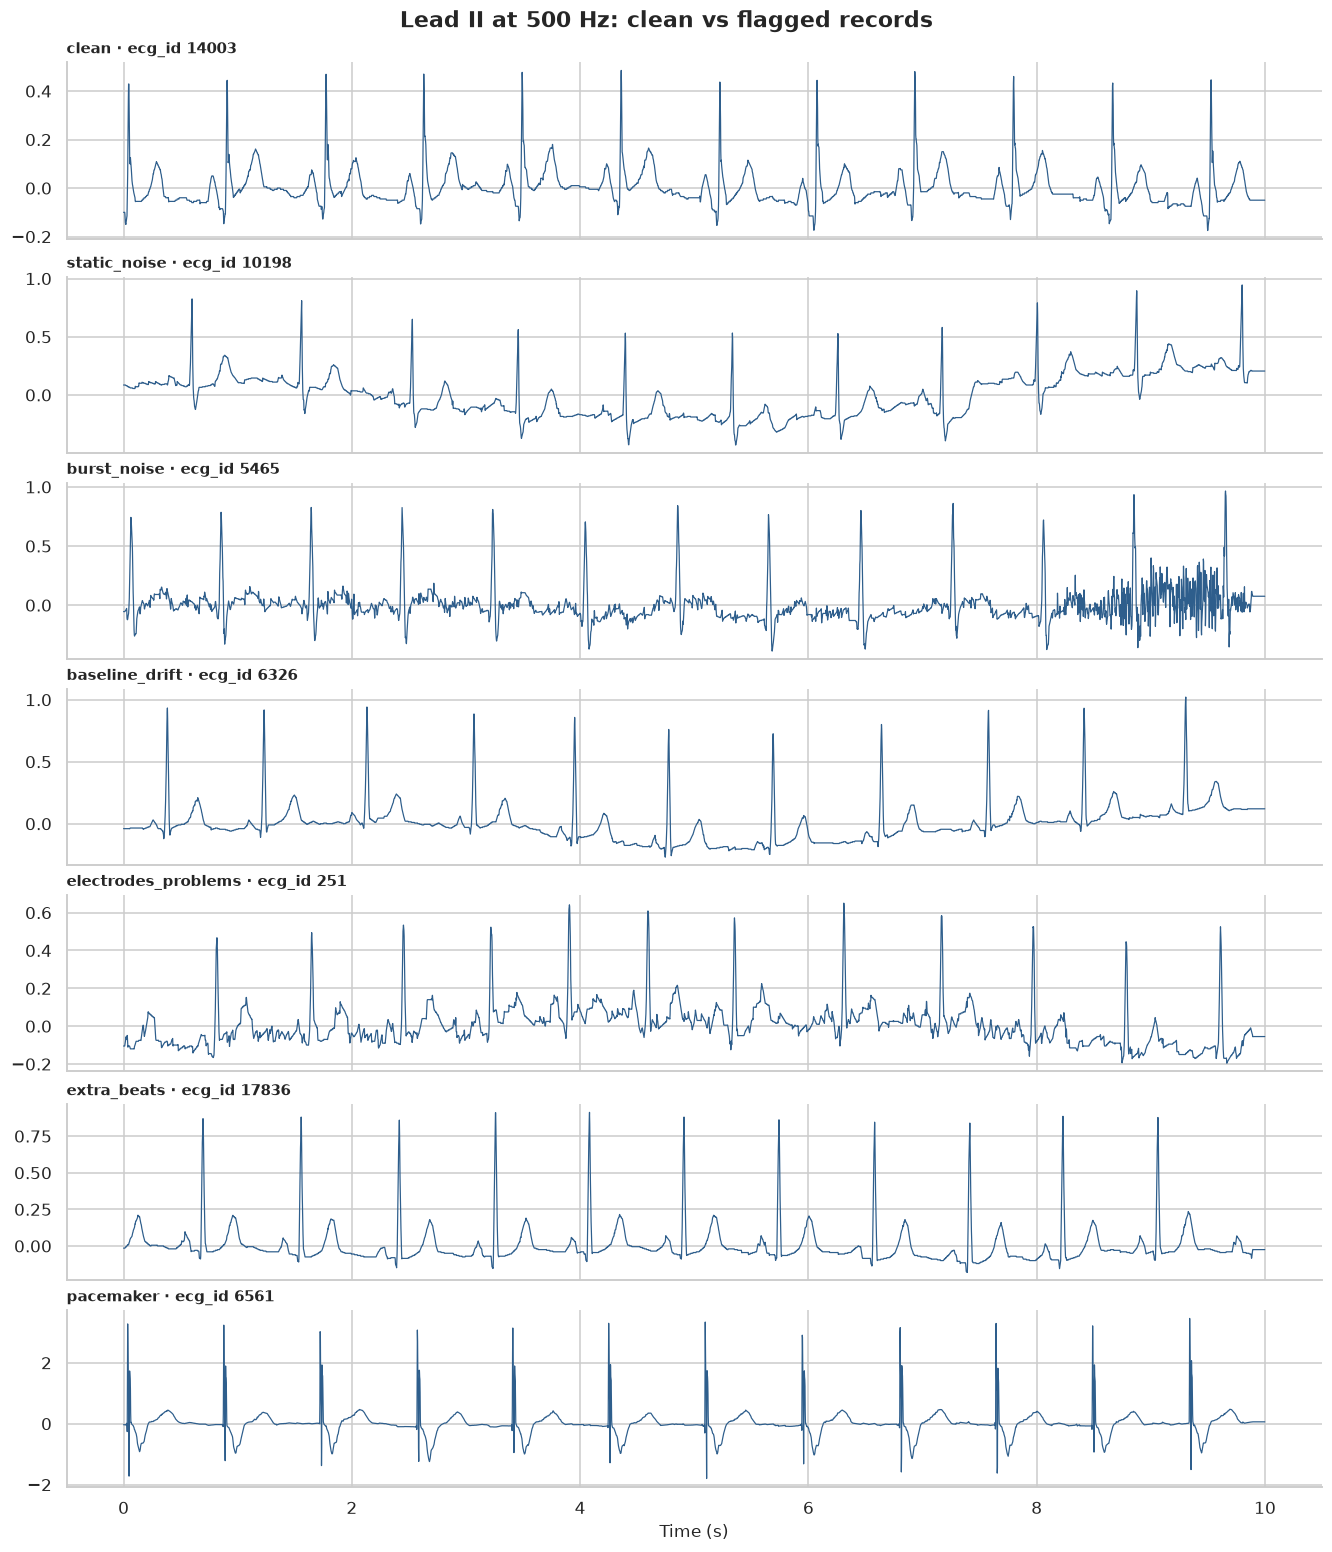

In [ ]:
comparison_ids = {"clean": selector.clean_record()} | {column: selector.flagged_record(column) for column in SIGNAL_QUALITY_COLUMNS}
comparison_signals = {f"{label} · ecg_id {ecg_id}": signals.load(ecg_id, HIGH_RATE) for label, ecg_id in comparison_ids.items()}
Charts.lead_comparison(comparison_signals, HIGH_RATE, LEAD_NAMES.index(REFERENCE_LEAD), f"Lead {REFERENCE_LEAD} at {HIGH_RATE} Hz: clean vs flagged records")